# **Лабораторная работа №2. Классификация. Нейронные сети**

## Введение

**Цель работы:** изучение методов классификации данных, реализованных в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

**Постановка задачи:**

1. Выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:
   - наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
   - деревья решений (Decision Tree);
   - линейный дискриминантный анализ (Linear Discriminant Analysis);
   - метод опорных векторов (Support Vector Machines);
   - метод ближайших соседей (k-Nearest Neighbors).
2. Сравнить качество работы классификаторов с помощью метрик Accuracy, Precision, Recall, F1-Score и площади под ROC-кривой (AUC-ROC).
3. Настроить гиперпараметры каждого метода и исследовать влияние различных параметров на качество классификации.
4. Реализовать и протестировать нейронную сеть на TensorFlow, исследовать эффект настройки гиперпараметров и визуализировать процесс обучения с помощью TensorBoard.

## 1. Выбор и подготовка датасета

Выбран датасет **«Caffeine Crash and Anxiety Telemetry»** — 8000 наблюдений о том, как человек перенёс порцию кофеина: кто он, что и сколько выпил, как отреагировал организм и насколько сильным был последующий «кофеиновый спад» (crash).

Столбцы:

- `user_id` — идентификатор участника (уникален для каждой строки);
- `age` — возраст, лет;
- `gender` — пол (Male / Female / Non-Binary);
- `cyp1a2_metabolizer_type` — тип метаболизма кофеина по ферменту CYP1A2 (Slow / Normal / Fast);
- `caffeine_tolerance` — привычная переносимость кофеина (Low / Moderate / High);
- `baseline_anxiety_score` — фоновый уровень тревожности, баллы 1–9.5;
- `prior_sleep_hours` — сколько часов человек спал накануне;
- `daily_hydration_liters` — выпито воды за день, л;
- `primary_caffeine_source` — источник кофеина (фильтр-кофе, эспрессо, энергетик с сахаром / без сахара, предтренировочный комплекс, матча / зелёный чай);
- `caffeine_mg` — доза кофеина, мг;
- `sugar_grams` — количество сахара в напитке, г;
- `consumption_duration_min` — за сколько минут напиток был выпит;
- `heart_rate_spike_bpm` — скачок пульса после употребления, уд/мин;
- `jitters_intensity_score` — выраженность тремора («дрожи»), баллы 1–10;
- `acute_anxiety_score` — острая тревожность после употребления, баллы 1–10;
- `crash_onset_hours` — через сколько часов наступил спад;
- `crash_severity_score` — тяжесть спада, баллы 1–10;
- `crash_risk_level` — уровень спада, 4 категории (исходная целевая переменная).

**Задача классификации:** по характеристикам человека, напитка и реакции организма предсказать, будет ли кофеиновый спад выраженным.

In [1]:
import os, shutil, time, warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # убираем служебные сообщения TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedKFold, validation_curve)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             confusion_matrix)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)   # фиксирует seed для Python, NumPy и TensorFlow

sns.set_theme(style='white')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
print('TF version:', tf.__version__)

TF version: 2.21.0


Импортируем необходимые модули: pandas / numpy — для работы с данными, scikit-learn — для классификаторов, метрик и предобработки, tensorflow / keras — для нейросети. Фиксируем `SEED = 42`, чтобы все случайные процессы (разбиение данных, кросс-валидация, инициализация весов нейросети) были воспроизводимыми. `keras.utils.set_random_seed` одновременно задаёт seed для Python, NumPy и TensorFlow.

In [2]:
DATA_PATH = 'caffeine_crash_and_anxiety_telemetry.csv'   # файл лежит рядом с ноутбуком
df = pd.read_csv(DATA_PATH)
print('Размер датасета:', df.shape)
print('\nТипы данных:')
print(df.dtypes)
df.head()

Размер датасета: (8000, 18)

Типы данных:
user_id                         str
age                           int64
gender                          str
cyp1a2_metabolizer_type         str
caffeine_tolerance              str
baseline_anxiety_score      float64
prior_sleep_hours           float64
daily_hydration_liters      float64
primary_caffeine_source         str
caffeine_mg                   int64
sugar_grams                 float64
consumption_duration_min      int64
heart_rate_spike_bpm        float64
jitters_intensity_score     float64
acute_anxiety_score         float64
crash_onset_hours           float64
crash_severity_score        float64
crash_risk_level                str
dtype: object


,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


Загружаем датасет: 8000 объектов, 18 столбцов. Из них 12 числовых (int64 / float64) и 6 строковых: идентификатор, четыре категориальных признака и целевая переменная `crash_risk_level`.

In [3]:
print('Пропуски по столбцам:')
print(df.isna().sum())
print('\nПолных дубликатов строк:', df.duplicated().sum())
print('Дубликатов user_id:', df['user_id'].duplicated().sum())
df.describe().T.round(2)

Пропуски по столбцам:
user_id                     0
age                         0
gender                      0
cyp1a2_metabolizer_type     0
caffeine_tolerance          0
baseline_anxiety_score      0
prior_sleep_hours           0
daily_hydration_liters      0
primary_caffeine_source     0
caffeine_mg                 0
sugar_grams                 0
consumption_duration_min    0
heart_rate_spike_bpm        0
jitters_intensity_score     0
acute_anxiety_score         0
crash_onset_hours           0
crash_severity_score        0
crash_risk_level            0
dtype: int64

Полных дубликатов строк: 0
Дубликатов user_id: 0


,count,mean,std,min,25%,50%,75%,max
age,8000.0,32.95,11.51,18.0,24.00,30.00,40.00,65.0
baseline_anxiety_score,8000.0,3.49,2.08,1.0,1.80,3.00,4.60,9.5
prior_sleep_hours,8000.0,6.38,1.29,3.2,5.50,6.40,7.30,9.5
daily_hydration_liters,8000.0,2.11,0.78,0.6,1.56,2.11,2.65,4.8
caffeine_mg,8000.0,198.04,65.87,40.0,157.00,195.00,234.00,420.0
sugar_grams,8000.0,18.03,19.13,0.0,0.80,10.50,34.60,62.0
consumption_duration_min,8000.0,28.98,20.49,3.0,10.00,26.00,45.00,107.0
heart_rate_spike_bpm,8000.0,4.67,4.00,2.0,2.00,2.50,6.20,35.7
jitters_intensity_score,8000.0,3.32,2.31,1.0,1.30,2.70,4.50,10.0
acute_anxiety_score,8000.0,3.68,2.37,1.0,1.70,3.20,5.10,10.0


Пропусков и дубликатов в данных нет. Признаки измерены в очень разных шкалах (кофеин — десятки и сотни мг, баллы тревожности — 1–10, вода — литры), поэтому для методов, чувствительных к масштабу (SVM, kNN, нейросеть), обязательна стандартизация.

In [4]:
print('Исходная целевая переменная crash_risk_level:')
print(df['crash_risk_level'].value_counts())

print('\nДиапазон crash_severity_score внутри каждого класса:')
print(df.groupby('crash_risk_level')['crash_severity_score'].agg(['min', 'max']).sort_values('min'))

Исходная целевая переменная crash_risk_level:
crash_risk_level
Moderate Crash & Lethargy       2426
Mild Afternoon Fatigue          2377
Severe Crash & Tachycardia      2161
Sustained / Negligible Crash    1036
Name: count, dtype: int64

Диапазон crash_severity_score внутри каждого класса:
                              min   max
crash_risk_level                       
Sustained / Negligible Crash  1.0   3.4
Mild Afternoon Fatigue        3.5   5.8
Moderate Crash & Lethargy     5.9   7.9
Severe Crash & Tachycardia    8.0  10.0


Важное наблюдение: диапазоны `crash_severity_score` для четырёх уровней `crash_risk_level` **не пересекаются** (1.0–3.4, 3.5–5.8, 5.9–7.9, 8.0–10.0). То есть целевая категория — это просто «нарезанный» по порогам балл тяжести. Если оставить `crash_severity_score` среди признаков, любая модель получит почти 100% точности, ничего не выучив о данных, — это **утечка целевой переменной** (data leakage). Поэтому этот столбец из признаков исключается.

Распределение классов:
target
1    4587
0    3413
Name: count, dtype: int64

Доли:
target
1    0.573
0    0.427
Name: proportion, dtype: float64


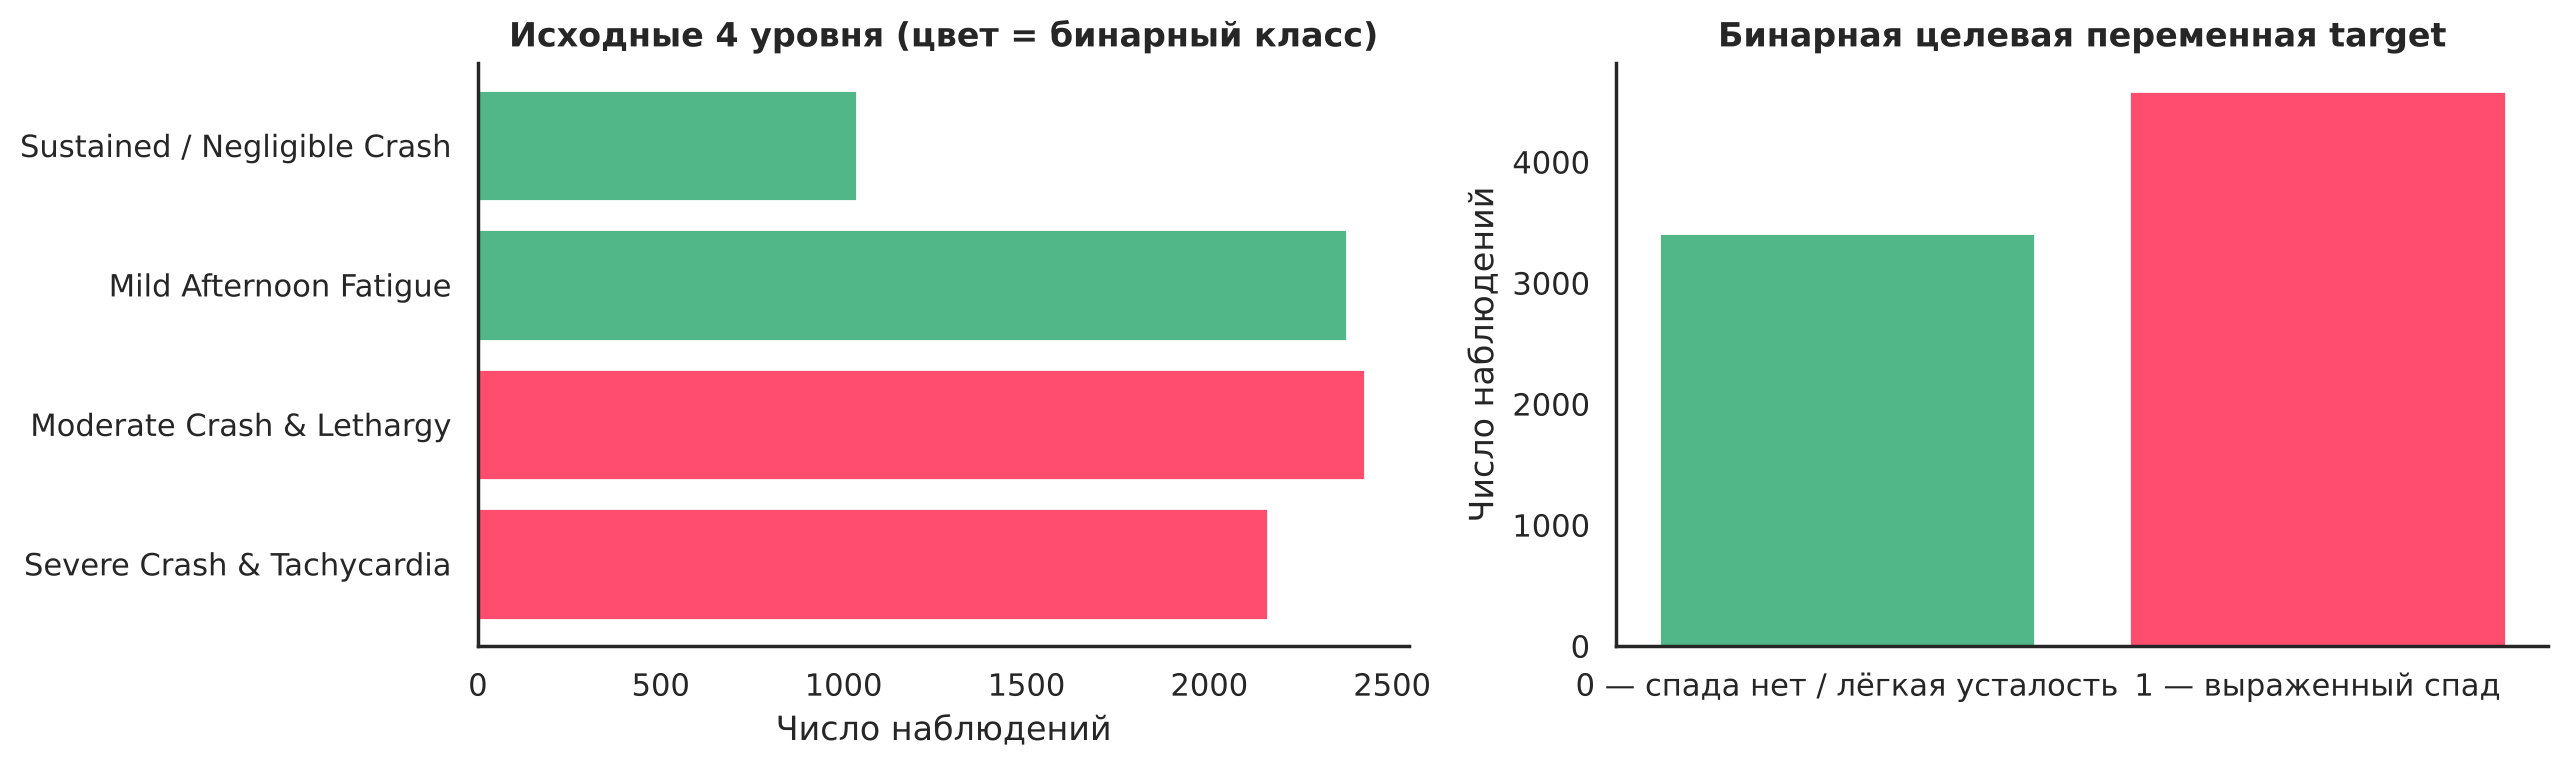

In [5]:
severe_levels = ['Moderate Crash & Lethargy', 'Severe Crash & Tachycardia']
df['target'] = df['crash_risk_level'].isin(severe_levels).astype(int)
target_names = {0: 'спада нет / лёгкая усталость', 1: 'выраженный спад'}

print('Распределение классов:')
print(df['target'].value_counts())
print('\nДоли:')
print(df['target'].value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = ['Sustained / Negligible Crash', 'Mild Afternoon Fatigue',
         'Moderate Crash & Lethargy', 'Severe Crash & Tachycardia']
cnt = df['crash_risk_level'].value_counts()[order]
axes[0].barh(order, cnt.values, color=['#52b788', '#52b788', '#ff4d6d', '#ff4d6d'])
axes[0].invert_yaxis()
axes[0].set_title('Исходные 4 уровня (цвет = бинарный класс)', fontweight='bold')
axes[0].set_xlabel('Число наблюдений')
vc = df['target'].value_counts().sort_index()
axes[1].bar(['0 — ' + target_names[0], '1 — ' + target_names[1]], vc.values,
            color=['#52b788', '#ff4d6d'])
axes[1].set_title('Бинарная целевая переменная target', fontweight='bold')
axes[1].set_ylabel('Число наблюдений')
plt.tight_layout(); plt.show()

Задание и набор метрик (precision, recall, ROC-кривая для «положительного» класса) рассчитаны на бинарную классификацию, поэтому четыре исходных уровня объединены в два класса:

- **target = 1 — выраженный спад**: `Moderate Crash & Lethargy` и `Severe Crash & Tachycardia`;
- **target = 0 — спада нет или он лёгкий**: `Sustained / Negligible Crash` и `Mild Afternoon Fatigue`.

Класс 1 — 4587 объектов (57.3%), класс 0 — 3413 (42.7%). Дисбаланс умеренный, поэтому при разбиении используем `stratify=y`, а качество оцениваем не только по accuracy, но и по F1 и AUC.

In [6]:
df_clean = df.drop(columns=['user_id', 'crash_severity_score', 'crash_risk_level']).copy()

# Защитная обработка пропусков: числовые -> медиана, категориальные -> мода
for col in df_clean.columns:
    if df_clean[col].isna().any():
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
        else:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

X = df_clean.drop(columns=['target'])
y = df_clean['target']

cat_features = ['gender', 'cyp1a2_metabolizer_type', 'caffeine_tolerance', 'primary_caffeine_source']
num_features = [c for c in X.columns if c not in cat_features]
print('X shape:', X.shape, '| y shape:', y.shape)
print('Пропусков после обработки:', df_clean.isna().sum().sum())
print('Категориальные:', cat_features)
print('Числовые:', num_features)

X shape: (8000, 15) | y shape: (8000,)
Пропусков после обработки: 0
Категориальные: ['gender', 'cyp1a2_metabolizer_type', 'caffeine_tolerance', 'primary_caffeine_source']
Числовые: ['age', 'baseline_anxiety_score', 'prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg', 'sugar_grams', 'consumption_duration_min', 'heart_rate_spike_bpm', 'jitters_intensity_score', 'acute_anxiety_score', 'crash_onset_hours']


Предобработка:

- удалены `user_id` (идентификатор не несёт информации), `crash_severity_score` (утечка) и исходный `crash_risk_level` (заменён на `target`);
- пропусков нет, но оставлена защитная обработка: числовые признаки заполнялись бы медианой, категориальные — модой;
- осталось 15 признаков: 11 числовых и 4 категориальных. Категориальные признаки номинальные (или с малым числом уровней), поэтому кодируются через One-Hot Encoding.

Замечание: признаки `heart_rate_spike_bpm`, `jitters_intensity_score`, `acute_anxiety_score` и `crash_onset_hours` измеряются уже после употребления напитка. Они оставлены, так как датасет позиционируется как телеметрия, по которой оценивается итог, но для прогноза *до* употребления их следовало бы исключить.

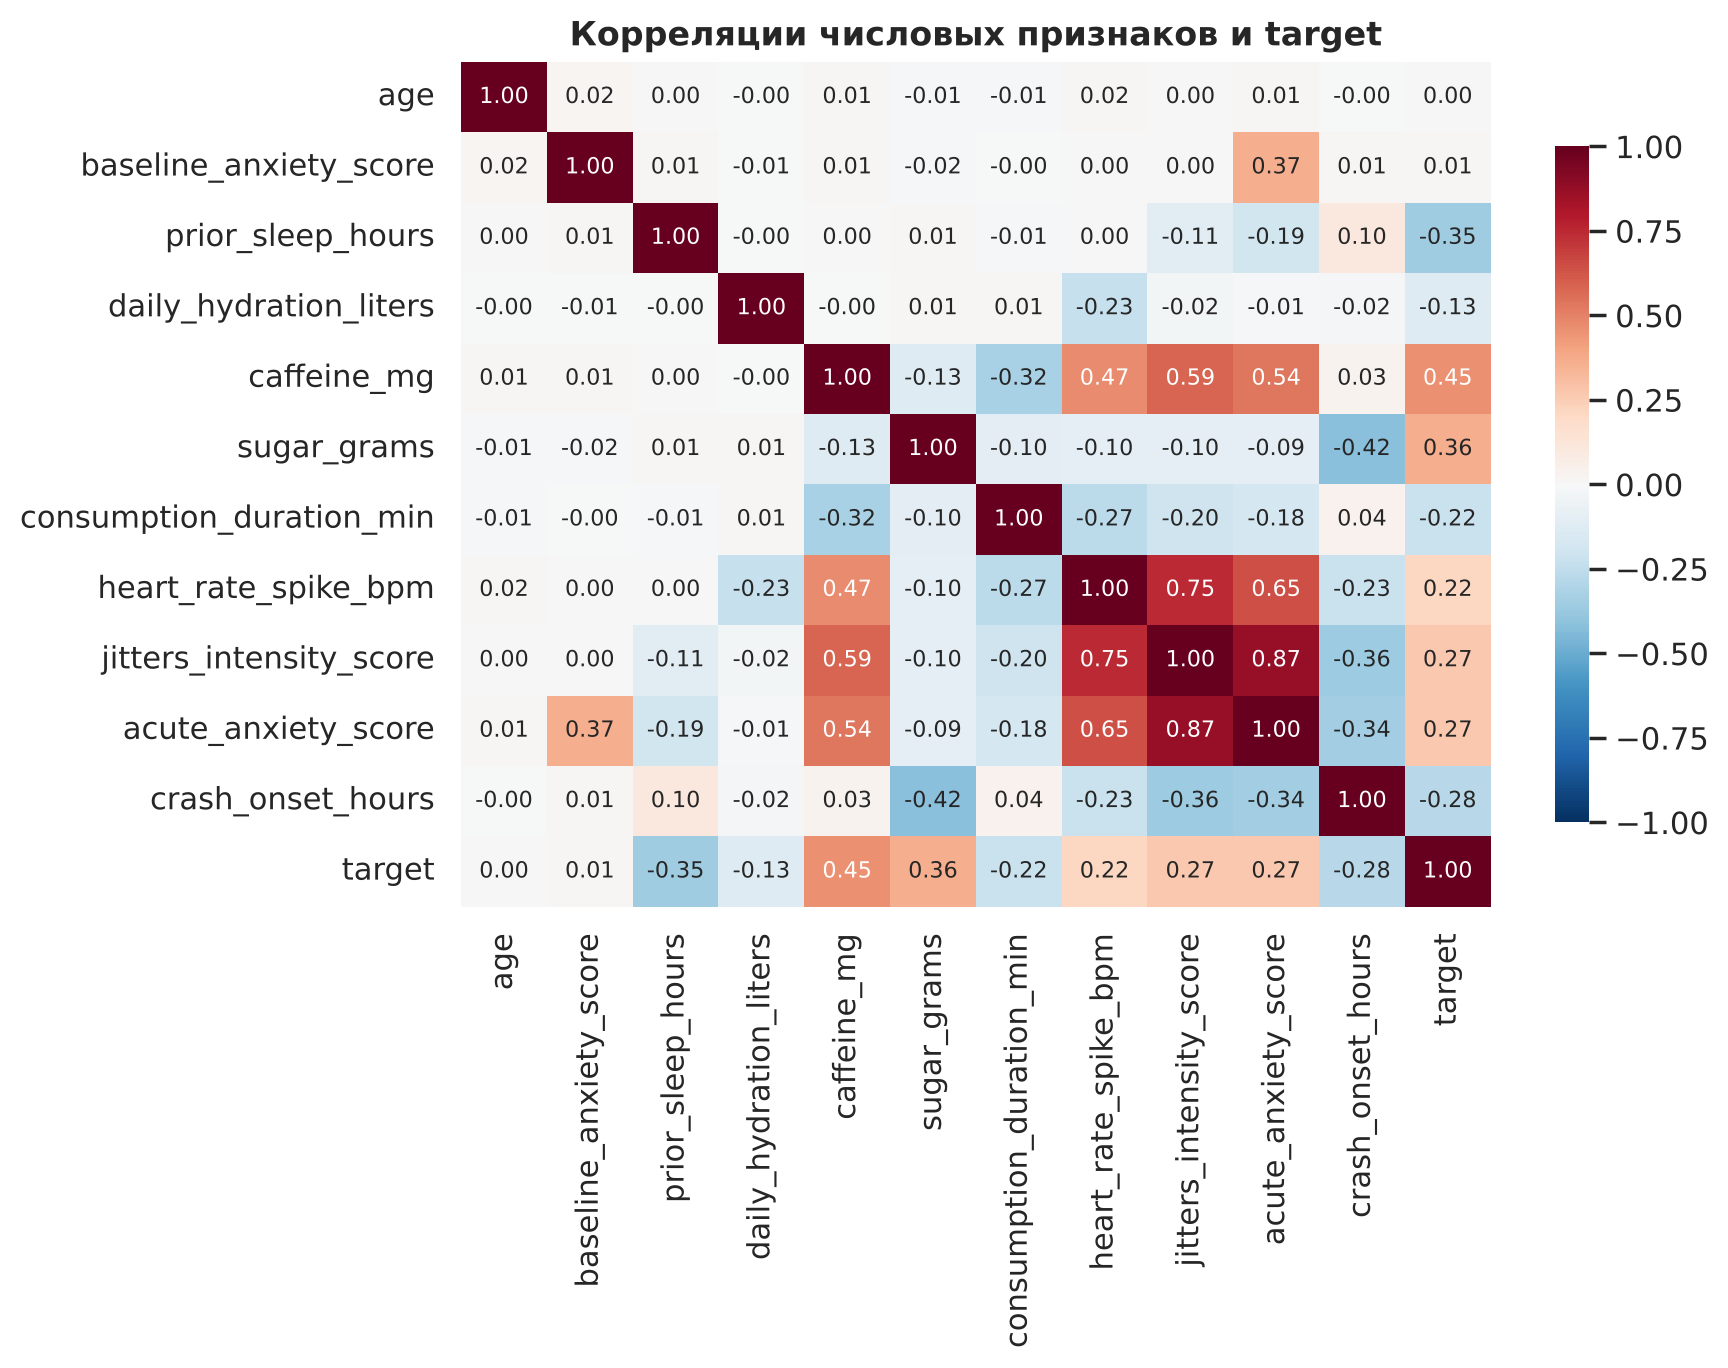

Корреляция признаков с target:
caffeine_mg                 0.453
sugar_grams                 0.361
prior_sleep_hours          -0.352
crash_onset_hours          -0.280
acute_anxiety_score         0.270
jitters_intensity_score     0.269
consumption_duration_min   -0.220
heart_rate_spike_bpm        0.217
daily_hydration_liters     -0.128
baseline_anxiety_score      0.009
age                         0.002
Name: target, dtype: float64


In [7]:
corr = df_clean[num_features + ['target']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot_kws={'size': 8}, cbar_kws={'shrink': 0.8})
plt.title('Корреляции числовых признаков и target', fontweight='bold')
plt.tight_layout(); plt.show()

print('Корреляция признаков с target:')
print(corr['target'].drop('target').sort_values(key=abs, ascending=False).round(3))

Сильнее всего с целевой переменной связаны доза кофеина (r = 0.45), сахар (0.36) и продолжительность сна накануне (−0.35): больше кофеина и сахара, меньше сна — выше риск выраженного спада. Возраст и фоновая тревожность с целью линейно почти не связаны (|r| < 0.01).

Признаки реакции организма сильно коррелируют между собой (`jitters_intensity_score` и `acute_anxiety_score` — 0.87, `heart_rate_spike_bpm` и `jitters_intensity_score` — 0.75). Это нарушает предположение наивного Байеса о независимости признаков — ниже видно, что именно он показывает худший результат.

## 2. Разбиение выборки

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Доли в train:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Доли в test :', y_test.value_counts(normalize=True).round(3).to_dict())

Train: (6400, 15) Test: (1600, 15)
Доли в train: {1: 0.573, 0: 0.427}
Доли в test : {1: 0.573, 0: 0.427}


80% данных (6400 объектов) — на обучение, 20% (1600) — на тест. `random_state=SEED` фиксирует разбиение, `stratify=y` сохраняет пропорции классов: в обеих выборках 57.3% / 42.7%. Тестовая выборка используется только для итоговой оценки; подбор гиперпараметров идёт кросс-валидацией внутри train.

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='drop'
)
X_train_prep = preprocessor.fit_transform(X_train).astype(np.float32)
X_test_prep  = preprocessor.transform(X_test).astype(np.float32)
feature_names = preprocessor.get_feature_names_out()

# Вариант с MinMaxScaler: неотрицательные признаки для MultinomialNB / ComplementNB
preprocessor_mm = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ],
    remainder='drop'
)
X_train_mm = preprocessor_mm.fit_transform(X_train)
X_test_mm  = np.clip(preprocessor_mm.transform(X_test), 0, None)

print('X_train_prep shape:', X_train_prep.shape)
print('X_test_prep shape :', X_test_prep.shape)

X_train_prep shape: (6400, 26)
X_test_prep shape : (1600, 26)


`ColumnTransformer` применяет:

- `StandardScaler` к числовым признакам (среднее 0, стандартное отклонение 1);
- `OneHotEncoder` к категориальным.

После кодирования получается 26 признаков (11 числовых + 3 + 3 + 3 + 6 бинарных столбцов). Критично: `fit` вызывается только на train, а `transform` — на train и test. Если обучать scaler на всех данных, информация о тесте «утечёт» в обучение.

Дополнительно подготовлен вариант с `MinMaxScaler` (значения в [0, 1]): MultinomialNB и ComplementNB требуют неотрицательных признаков и не работают со стандартизованными данными.

## 3. Методы классификации

**Наивный Байесовский классификатор.** Применяет теорему Байеса, предполагая условную независимость признаков при известном классе: P(y | x) ∝ P(y) · ∏ P(xᵢ | y). Варианты различаются моделью P(xᵢ | y): GaussianNB — нормальное распределение (непрерывные признаки), MultinomialNB — мультиномиальное (счётчики, частоты слов), ComplementNB — модификация мультиномиального для несбалансированных классов, BernoulliNB — распределение Бернулли (бинарные признаки).

**Дерево решений.** Рекурсивно делит пространство признаков порогами вида «признак ≤ значение», выбирая разбиение, которое сильнее всего уменьшает неоднородность (критерий Джини или энтропия). Не требует масштабирования, интерпретируемо, но без ограничений глубины легко переобучается.

**Линейный дискриминантный анализ (LDA).** Предполагает, что признаки в каждом классе распределены нормально с общей ковариационной матрицей; в этом случае оптимальная граница между классами линейна. В отличие от наивного Байеса учитывает корреляции между признаками.

**Метод опорных векторов (SVM).** Строит разделяющую гиперплоскость с максимальным зазором между классами; параметр C задаёт штраф за ошибки. Ядро (RBF, полиномиальное и др.) позволяет получать нелинейные границы.

**Метод ближайших соседей (kNN).** Относит объект к классу, преобладающему среди k ближайших обучающих объектов. Модель не обучается в привычном смысле, а запоминает выборку; чувствителен к масштабу признаков и выбору k.

### 3.1. Выбор варианта наивного Байеса

In [10]:
def get_metrics(y_true, y_pred, y_proba):
    return [accuracy_score(y_true, y_pred),
            precision_score(y_true, y_pred, pos_label=1),
            recall_score(y_true, y_pred, pos_label=1),
            f1_score(y_true, y_pred, pos_label=1),
            roc_auc_score(y_true, y_proba)]

METRIC_COLS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

nb_variants = {
    'GaussianNB (StandardScaler)':   (GaussianNB(),              X_train_prep, X_test_prep),
    'MultinomialNB (MinMaxScaler)':  (MultinomialNB(),           X_train_mm,   X_test_mm),
    'ComplementNB (MinMaxScaler)':   (ComplementNB(),            X_train_mm,   X_test_mm),
    'BernoulliNB (binarize=0)':      (BernoulliNB(binarize=0.0), X_train_prep, X_test_prep),
}
rows = []
for name, (m, Xtr, Xte) in nb_variants.items():
    m.fit(Xtr, y_train)
    rows.append([name] + get_metrics(y_test, m.predict(Xte), m.predict_proba(Xte)[:, 1]))
nb_df = pd.DataFrame(rows, columns=['Model'] + METRIC_COLS).set_index('Model')
print(nb_df.round(4))

                              Accuracy  Precision  Recall      F1     AUC
Model                                                                    
GaussianNB (StandardScaler)     0.8088     0.8022  0.8844  0.8413  0.8705
MultinomialNB (MinMaxScaler)    0.7831     0.7944  0.8386  0.8159  0.8623
ComplementNB (MinMaxScaler)     0.7887     0.8279  0.7972  0.8122  0.8623
BernoulliNB (binarize=0)        0.8031     0.8142  0.8506  0.8320  0.8851


Сравнение четырёх вариантов наивного Байеса на тестовой выборке:

- **GaussianNB** — лучший по accuracy (0.809), recall (0.884) и F1 (0.841). Это ожидаемо: большинство признаков непрерывные, и нормальное распределение — естественная модель для них.
- **BernoulliNB** — бинаризует каждый признак по порогу 0 (после стандартизации это «выше / ниже среднего»). Теряет информацию о величине, но F1 = 0.832 и неожиданно лучший AUC (0.885).
- **MultinomialNB / ComplementNB** — рассчитаны на счётчики (например, частоты слов), а не на непрерывные величины; дают F1 0.816 и 0.812. ComplementNB при этом имеет наибольшую precision (0.828), но наименьший recall (0.797).

Для дальнейшего сравнения с другими методами используется **GaussianNB** как наиболее корректный для данных и лучший по F1.

### 3.2. Пять методов с базовыми параметрами

In [11]:
models = {
    'GaussianNB': GaussianNB(),
    'DecisionTree': DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=SEED),
    'kNN': KNeighborsClassifier(n_neighbors=5),
}

results, roc_data, proba_data = [], {}, {}
for name, model in models.items():
    model.fit(X_train_prep, y_train)
    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]
    results.append([name] + get_metrics(y_test, y_pred, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=1)
    roc_data[name] = (fpr, tpr, results[-1][-1])
    proba_data[name] = y_proba

results_df = pd.DataFrame(results, columns=['Model'] + METRIC_COLS)
print(results_df.round(4).to_string(index=False))

tree = models['DecisionTree']
print('\nГлубина дерева:', tree.get_depth(), '| листьев:', tree.get_n_leaves(),
      '| узлов:', tree.tree_.node_count)

       Model  Accuracy  Precision  Recall     F1    AUC
  GaussianNB    0.8088     0.8022  0.8844 0.8413 0.8705
DecisionTree    0.8206     0.8446  0.8419 0.8433 0.9136
         LDA    0.9131     0.9192  0.9302 0.9247 0.9756
         SVM    0.9300     0.9277  0.9520 0.9397 0.9803
         kNN    0.8681     0.8788  0.8931 0.8859 0.9328

Глубина дерева: 5 | листьев: 31 | узлов: 61


Для каждой из 5 моделей: обучаем на train, получаем предсказания и вероятности на test. Метрики считаются для положительного класса (`pos_label=1`, выраженный спад). AUC-ROC считается по `predict_proba[:, 1]`; для SVM для этого обязателен параметр `probability=True`.

Уже с параметрами по умолчанию видно расслоение: **SVM** (F1 = 0.940, AUC = 0.980) и **LDA** (0.925 / 0.976) заметно впереди, **kNN** посередине (0.886 / 0.933), **дерево** (0.843 / 0.914) и **GaussianNB** (0.841 / 0.871) замыкают список.

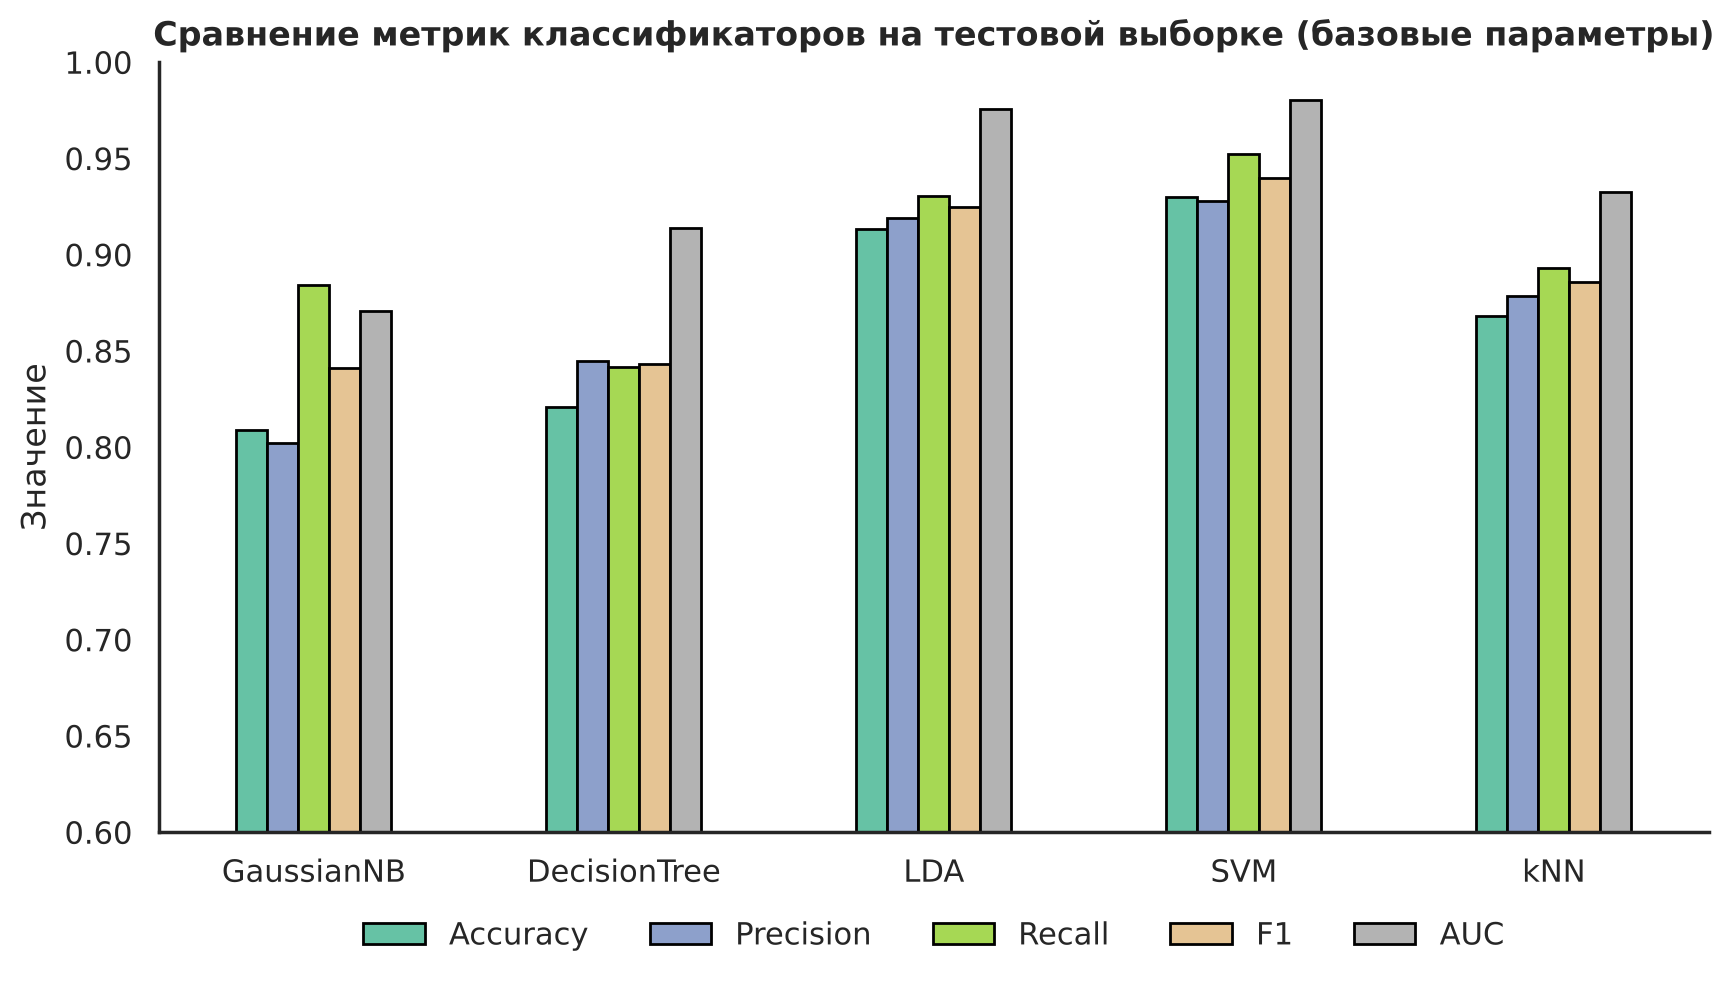

In [12]:
ax = results_df.set_index('Model')[METRIC_COLS].plot(
    kind='bar', figsize=(10, 5), ylim=(0.6, 1.0), colormap='Set2', edgecolor='black'
)
plt.title('Сравнение метрик классификаторов на тестовой выборке (базовые параметры)', fontweight='bold')
plt.ylabel('Значение'); plt.xlabel(''); plt.xticks(rotation=0)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=5, frameon=False)
plt.show()

Столбчатая диаграмма показывает 5 метрик для 5 моделей. У GaussianNB заметен перекос: recall (0.88) существенно выше precision (0.80) — модель склонна «перестраховываться» и относить объекты к классу 1. У остальных моделей precision и recall сбалансированы. Все модели оценены на одной и той же тестовой выборке, поэтому сравнение корректно.

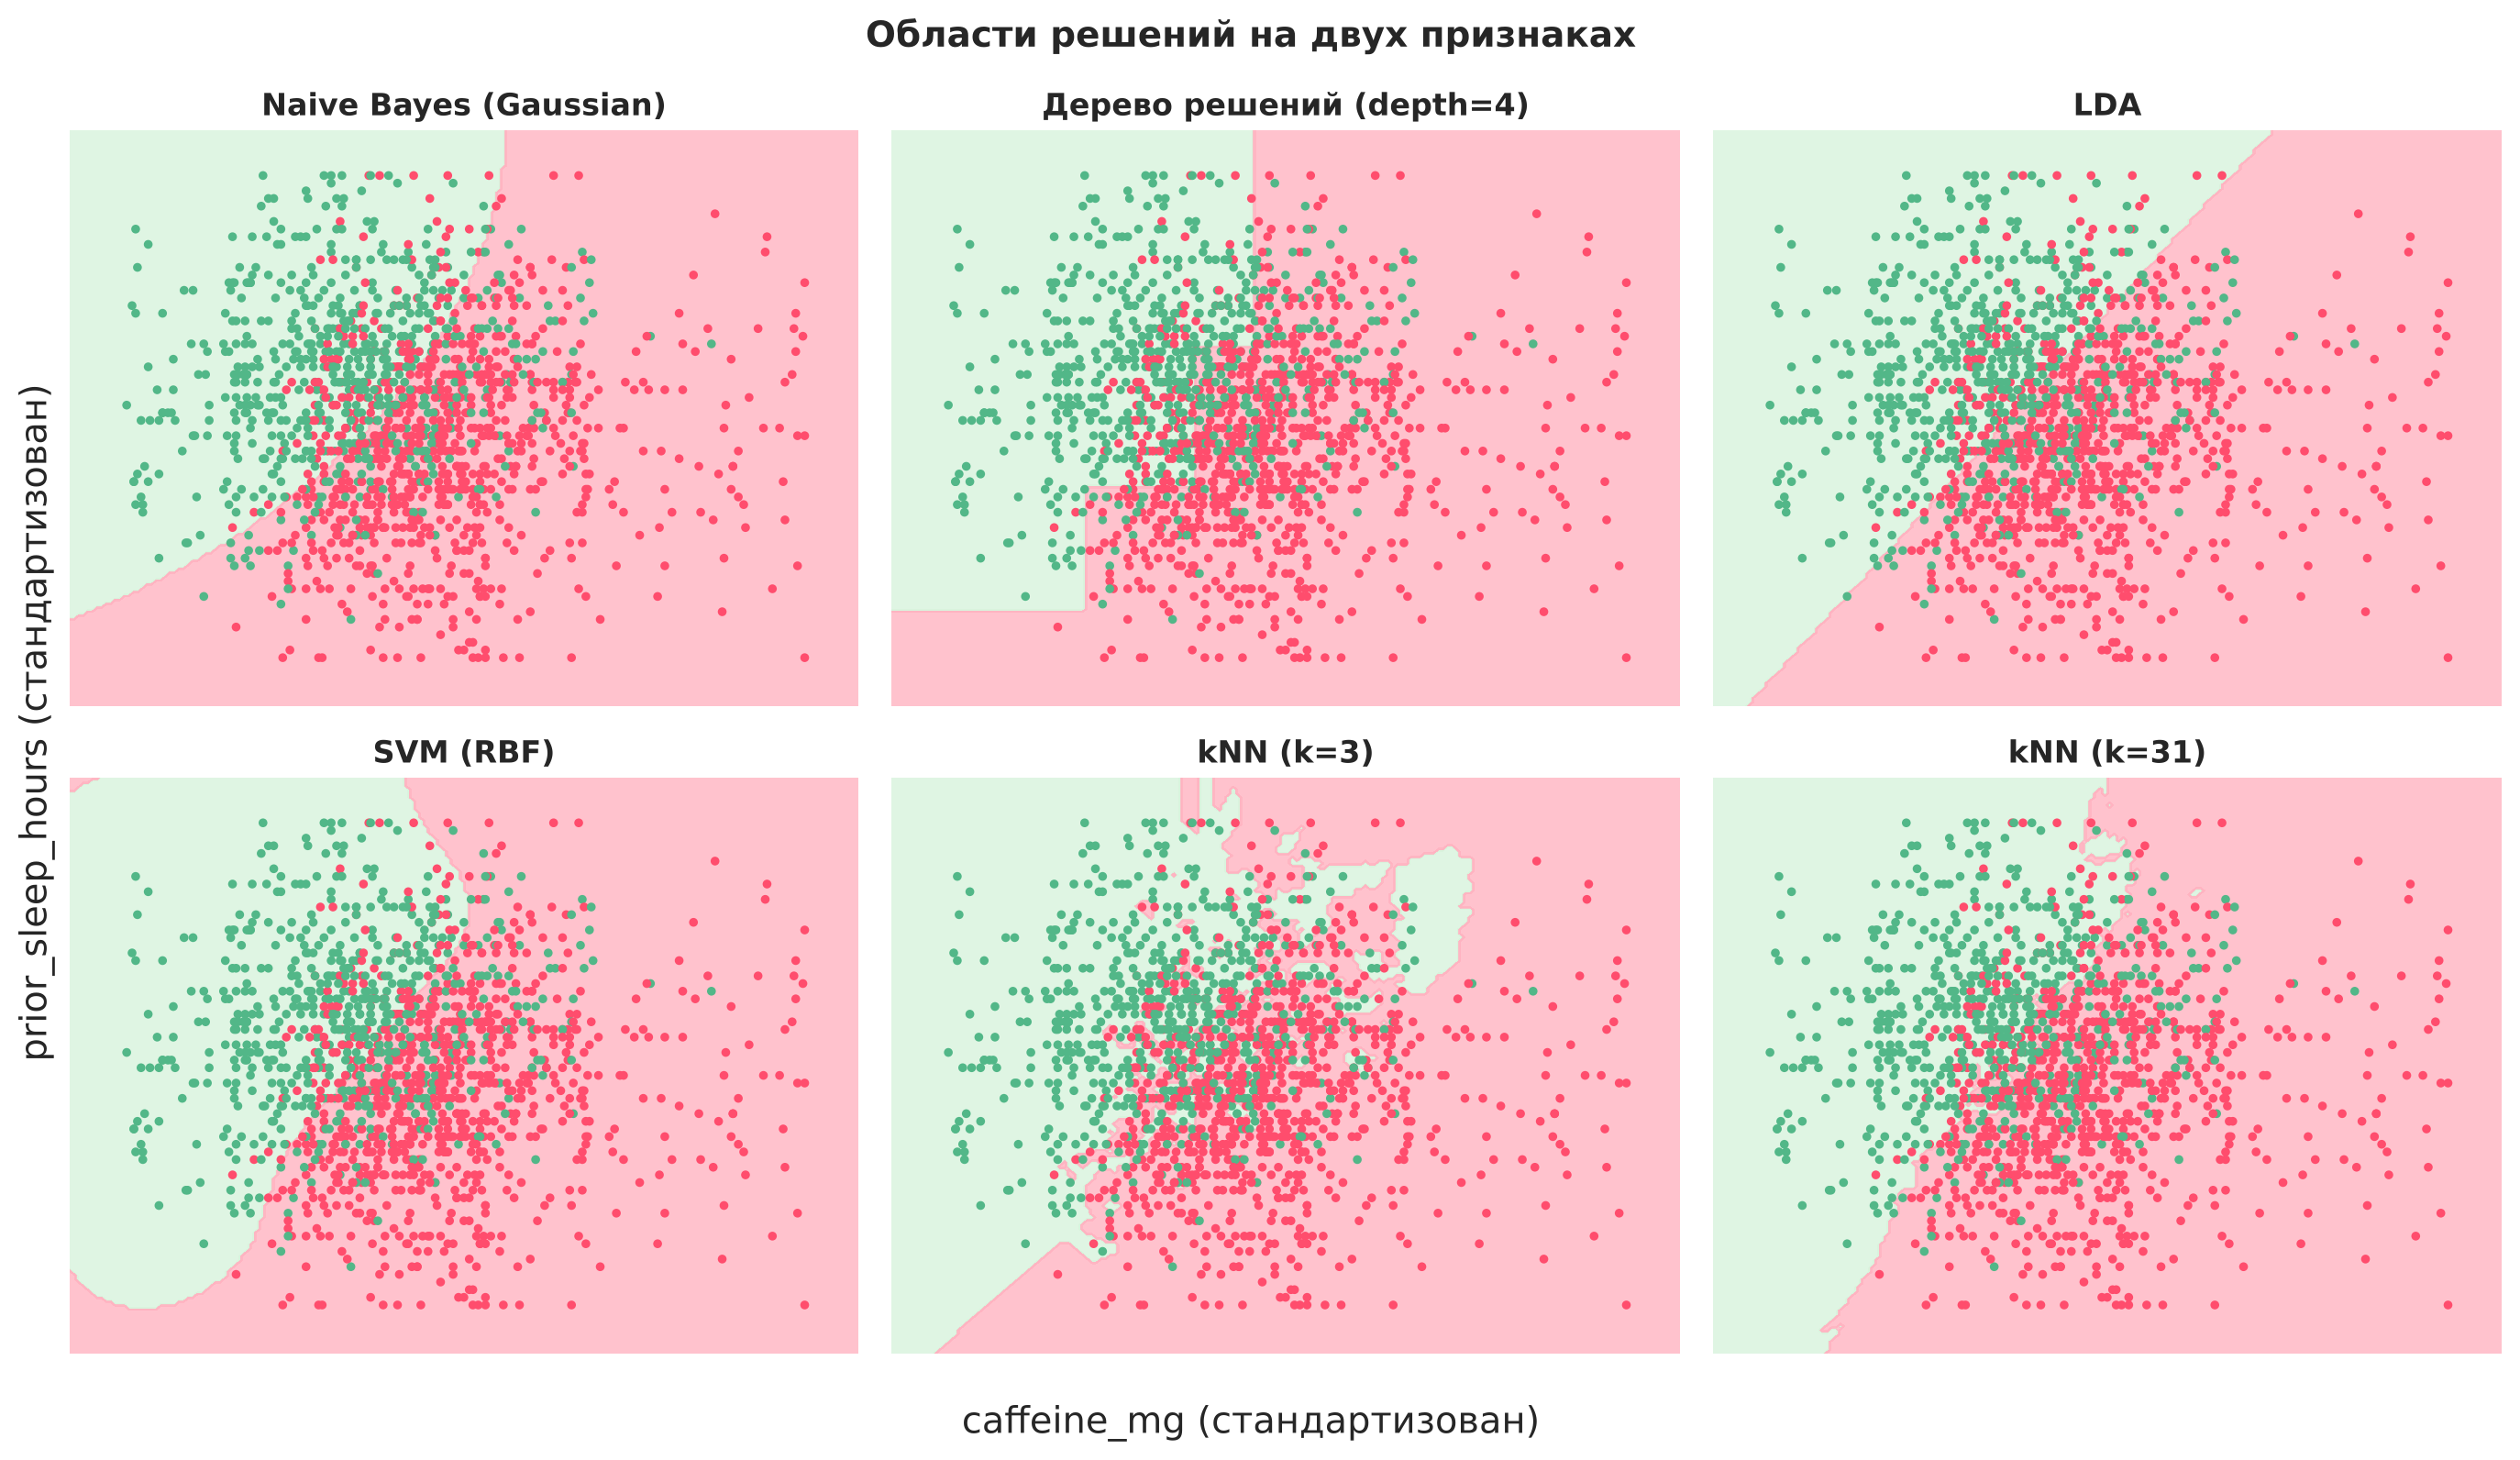

In [13]:
feature_1, feature_2 = 'caffeine_mg', 'prior_sleep_hours'
vis_idx = X_train.sample(1500, random_state=SEED).index      # подвыборка, чтобы график читался
X_vis = StandardScaler().fit_transform(X_train.loc[vis_idx, [feature_1, feature_2]].values)
y_vis = y_train.loc[vis_idx].values

cmap_light = ListedColormap(['#d8f3dc', '#ffb3c1'])
cmap_bold  = ListedColormap(['#52b788', '#ff4d6d'])
x_min, x_max = X_vis[:, 0].min() - 0.5, X_vis[:, 0].max() + 0.5
y_min, y_max = X_vis[:, 1].min() - 0.5, X_vis[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.04), np.arange(y_min, y_max, 0.04))

models_vis = {
    'Naive Bayes (Gaussian)': GaussianNB(),
    'Дерево решений (depth=4)': DecisionTreeClassifier(max_depth=4, random_state=SEED),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM (RBF)': SVC(kernel='rbf', gamma=1.0, C=1.0),
    'kNN (k=3)': KNeighborsClassifier(n_neighbors=3),
    'kNN (k=31)': KNeighborsClassifier(n_neighbors=31),
}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, model) in zip(axes.ravel(), models_vis.items()):
    model.fit(X_vis, y_vis)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
    ax.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, cmap=cmap_bold, s=6)
    ax.set_title(name, fontweight='bold', fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.supxlabel(f'{feature_1} (стандартизован)'); fig.supylabel(f'{feature_2} (стандартизован)')
plt.suptitle('Области решений на двух признаках', fontweight='bold', fontsize=14)
plt.tight_layout(); plt.show()

Для визуализации областей решений взяты два самых информативных признака — доза кофеина и часы сна (на плоскости можно показать только два). Модели здесь обучены только на этих двух признаках, поэтому рисунок иллюстрирует *характер* границ, а не итоговое качество:

- **LDA** — прямая линия;
- **GaussianNB** — гладкая кривая (квадратичная граница, так как дисперсии в классах разные);
- **дерево** — ступенчатая граница из отрезков, параллельных осям;
- **SVM (RBF)** — гладкая нелинейная граница;
- **kNN** — при k = 3 граница изрезанная, с «островками» вокруг отдельных точек (переобучение), при k = 31 — сглаженная.

Общая закономерность видна на всех панелях: много кофеина и мало сна (правый нижний угол) — выраженный спад.

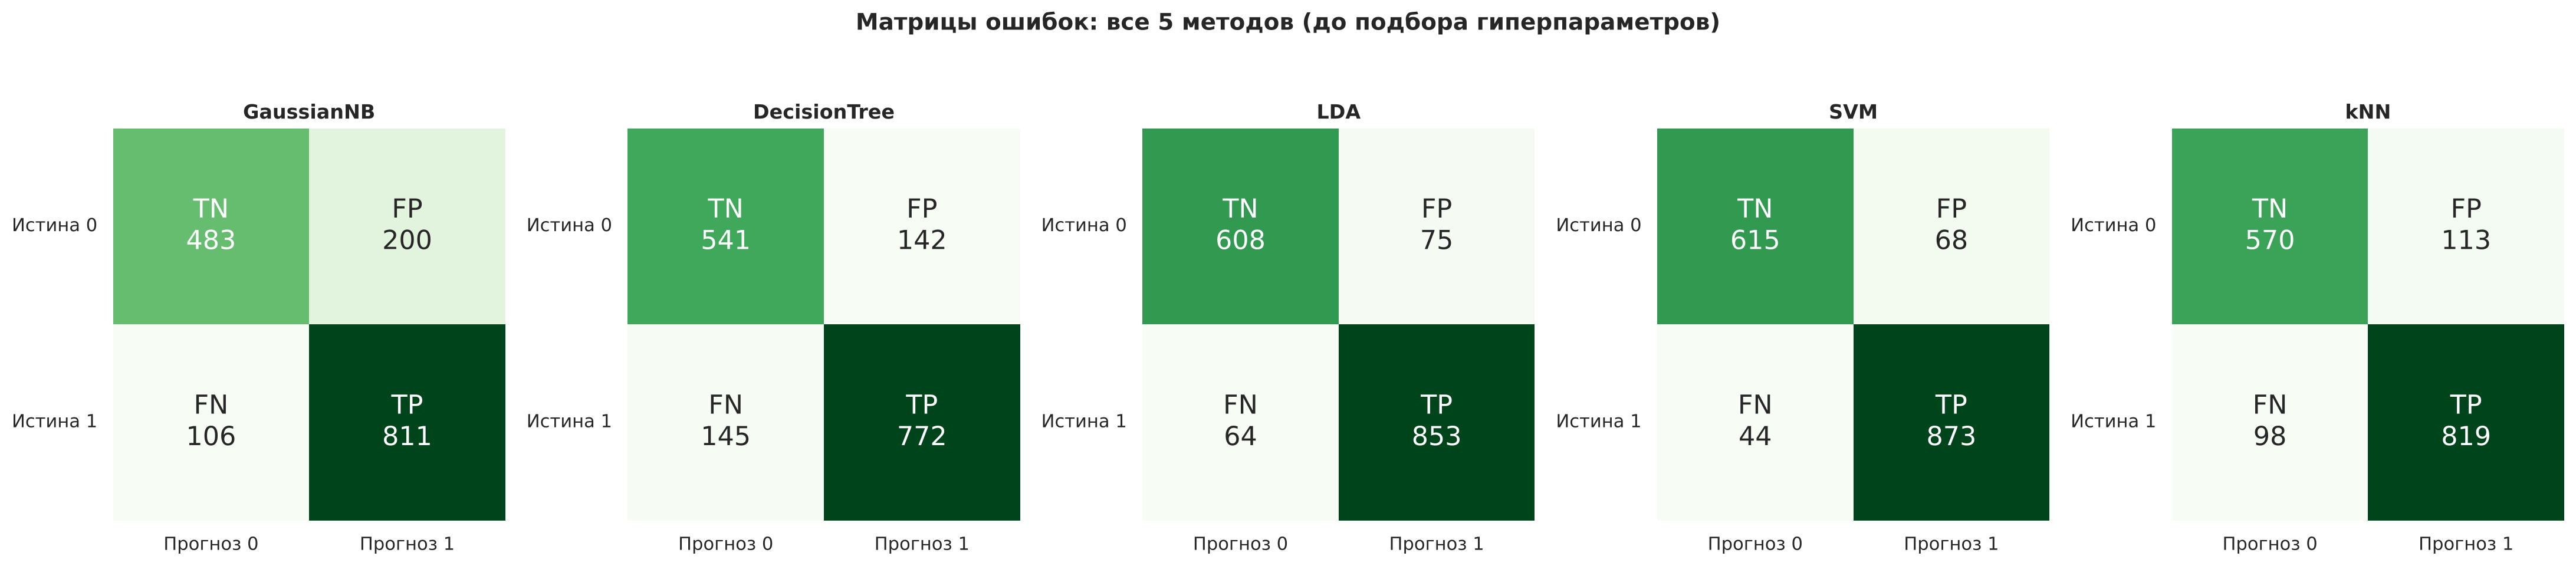

In [14]:
def plot_confusions(model_dict, title, cmap):
    fig, axes = plt.subplots(1, len(model_dict), figsize=(4.4 * len(model_dict), 4.5))
    for ax, (name, model) in zip(axes, model_dict.items()):
        cm = confusion_matrix(y_test, model.predict(X_test_prep))
        labels = np.asarray([f'{g}\n{v}' for g, v in zip(['TN', 'FP', 'FN', 'TP'], cm.flatten())]).reshape(2, 2)
        sns.heatmap(cm, annot=labels, fmt='', cmap=cmap, cbar=False, square=True,
                    annot_kws={'size': 16},
                    xticklabels=['Прогноз 0', 'Прогноз 1'],
                    yticklabels=['Истина 0', 'Истина 1'], ax=ax)
        ax.set_title(name, fontweight='bold', fontsize=12)
        ax.set_yticklabels(['Истина 0', 'Истина 1'], rotation=0)
    plt.suptitle(title, fontweight='bold', fontsize=14, y=1.05)
    plt.tight_layout(); plt.show()

plot_confusions(models, 'Матрицы ошибок: все 5 методов (до подбора гиперпараметров)', 'Greens')

Матрицы ошибок на тестовой выборке (базовые параметры). Как читать:

- TN — спада не было, и модель его не предсказала;
- TP — выраженный спад верно предсказан;
- FP — ложная тревога: предсказан спад, которого не было;
- FN — пропуск: спад был, но модель его не предсказала.

У GaussianNB больше всего ложных тревог (FP = 200 при FN = 106) — отсюда низкая precision. У дерева ошибки распределены поровну (142 / 145). Самые «чистые» диагонали — у SVM (FP = 68, FN = 44) и LDA (75 / 64).

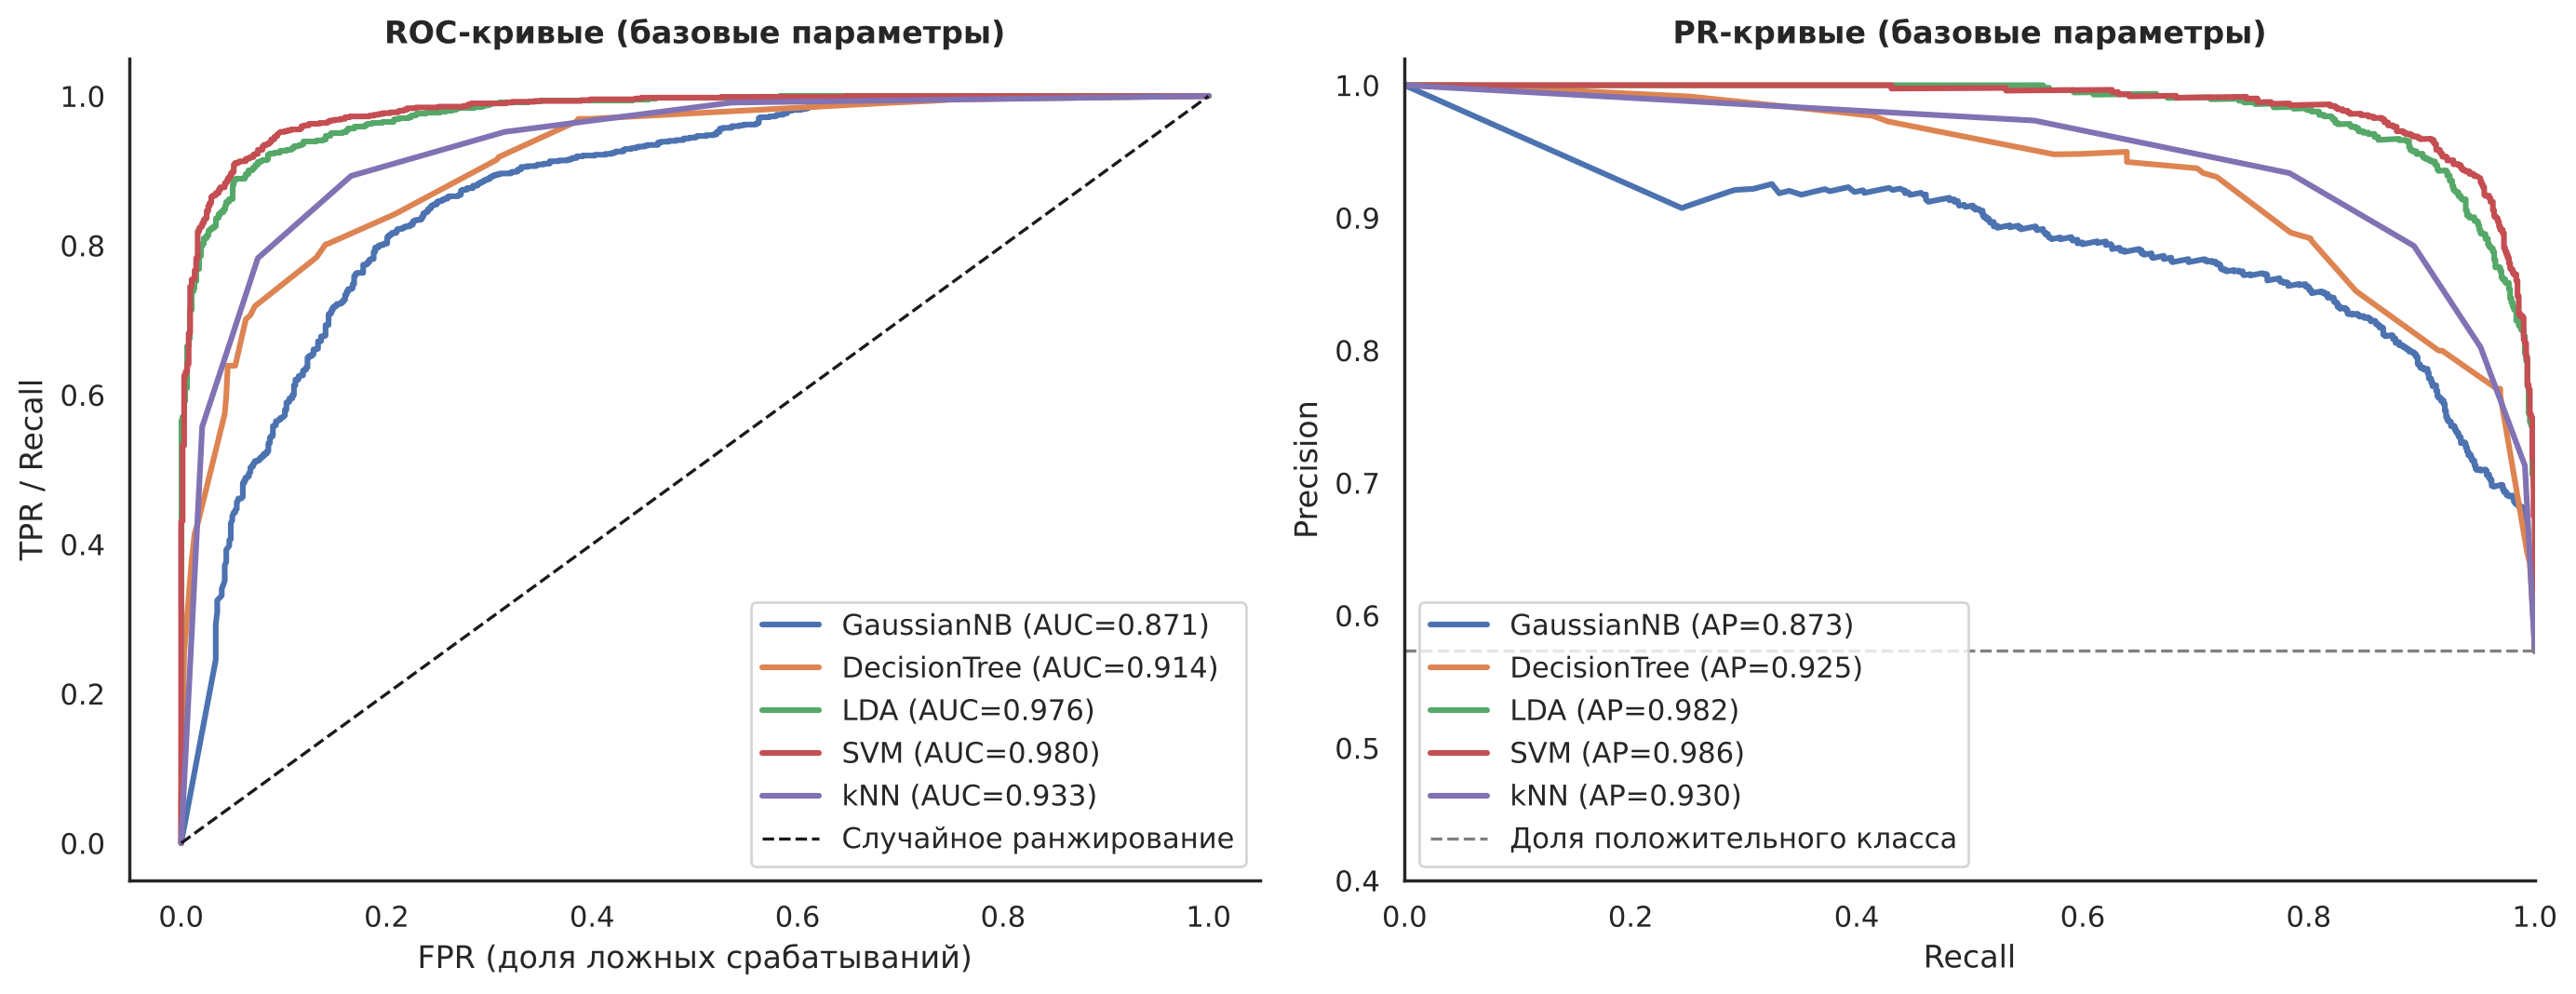

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, (fpr, tpr, auroc) in roc_data.items():
    axes[0].plot(fpr, tpr, lw=2.2, label=f'{name} (AUC={auroc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Случайное ранжирование')
axes[0].set_xlabel('FPR (доля ложных срабатываний)')
axes[0].set_ylabel('TPR / Recall')
axes[0].set_title('ROC-кривые (базовые параметры)', fontweight='bold')
axes[0].legend(loc='lower right')

for name in models:
    p, r, _ = precision_recall_curve(y_test, proba_data[name], pos_label=1)
    ap = average_precision_score(y_test, proba_data[name])
    axes[1].plot(r, p, lw=2.2, label=f'{name} (AP={ap:.3f})')
axes[1].axhline(y=y_test.mean(), color='gray', lw=1.2, linestyle='--', label='Доля положительного класса')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0.4, 1.02])
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR-кривые (базовые параметры)', fontweight='bold')
axes[1].legend(loc='lower left')
plt.tight_layout(); plt.show()

**ROC-кривая** строится при изменении порога классификации от 1 до 0: по оси X — FPR = FP / (FP + TN), по оси Y — TPR = TP / (TP + FN) = recall. Площадь под кривой (AUC) — интегральная мера качества ранжирования: 0.5 — случайный классификатор, 1.0 — идеальный. Кривые SVM и LDA почти сливаются и проходят ближе всех к левому верхнему углу (AUC 0.980 и 0.976); кривая GaussianNB лежит заметно ниже (0.871).

**PR-кривая** показывает компромисс между precision и recall при изменении порога; пунктир — доля положительного класса (precision «наивного» классификатора, который всех относит к классу 1). Порядок моделей тот же: SVM (AP = 0.986) и LDA (0.982) удерживают precision выше 0.95 почти до recall = 0.9, у GaussianNB precision падает уже при малых значениях recall.

## 4. Настройка гиперпараметров

### 4.1. Подбор по сетке (GridSearchCV)

In [16]:
param_grids = {
    'GaussianNB': {'var_smoothing': [1e-12, 1e-9, 1e-6, 1e-3, 1e-2, 1e-1, 1.0]},
    'DecisionTree': {
        'criterion': ['gini', 'entropy'],
        'max_depth': [3, 5, 7, 10, None],
        'min_samples_split': [2, 10, 50],
        'min_samples_leaf': [1, 5, 20],
    },
    'LDA': [
        {'solver': ['svd']},
        {'solver': ['lsqr', 'eigen'], 'shrinkage': [None, 'auto', 0.1, 0.5, 0.9]},
    ],
    'SVM': [
        {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1]},
        {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    ],
    'kNN': {'n_neighbors': [3, 5, 7, 11, 15, 21, 31], 'weights': ['uniform', 'distance'], 'p': [1, 2]},
}
base_models = {
    'GaussianNB': GaussianNB(),
    'DecisionTree': DecisionTreeClassifier(random_state=SEED),
    'LDA': LinearDiscriminantAnalysis(),
    'SVM': SVC(random_state=SEED),          # probability включим при финальном обучении
    'kNN': KNeighborsClassifier(),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Для каждого метода задано своё пространство гиперпараметров:

- **GaussianNB** — `var_smoothing`: добавка к дисперсиям признаков (доля от наибольшей дисперсии). Нужна для численной устойчивости; большие значения сглаживают распределения.
- **DecisionTree** — `criterion` (Джини / энтропия), `max_depth` (ограничение глубины), `min_samples_split` и `min_samples_leaf` (минимальный размер узла для разбиения и листа). Все три ограничения борются с переобучением.
- **LDA** — `solver` (svd / lsqr / eigen) и `shrinkage` — регуляризация оценки ковариационной матрицы (доступна только для lsqr и eigen).
- **SVM** — `kernel` (rbf / linear), `C` (штраф за ошибки: чем больше, тем сложнее граница), `gamma` (ширина RBF-ядра: чем больше, тем более локальна граница).
- **kNN** — `n_neighbors` (число соседей k), `weights` (равные веса или обратно пропорциональные расстоянию), `p` (метрика: 1 — манхэттенская, 2 — евклидова).

Кросс-валидация — стратифицированная, 5 фолдов.

In [17]:
best_models, grid_results = {}, {}
for name, base in base_models.items():
    t0 = time.time()
    gs = GridSearchCV(base, param_grids[name], cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(X_train_prep, y_train)
    grid_results[name] = gs
    best = gs.best_estimator_
    if name == 'SVM':                        # переобучаем лучший SVM с оценкой вероятностей
        best = SVC(**gs.best_params_, probability=True, random_state=SEED).fit(X_train_prep, y_train)
    best_models[name] = best
    print(f'{name}: best={gs.best_params_}  cv_f1={gs.best_score_:.4f}  ({time.time() - t0:.0f} c)')

GaussianNB: best={'var_smoothing': 0.001}  cv_f1=0.8412  (1 c)


DecisionTree: best={'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 20, 'min_samples_split': 2}  cv_f1=0.8862  (5 c)


LDA: best={'solver': 'svd'}  cv_f1=0.9126  (0 c)


SVM: best={'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}  cv_f1=0.9224  (15 c)


kNN: best={'n_neighbors': 31, 'p': 2, 'weights': 'distance'}  cv_f1=0.8815  (6 c)


`GridSearchCV` перебирает все комбинации гиперпараметров и для каждой считает среднюю F1 по 5 фолдам кросс-валидации на обучающей выборке; тестовая выборка в подборе не участвует. Метрика подбора — F1, так как она балансирует precision и recall и устойчивее accuracy при неравных классах.

Лучшие параметры:

- **GaussianNB**: `var_smoothing = 0.001` (CV F1 = 0.841) — почти не отличается от значения по умолчанию;
- **DecisionTree**: энтропия, `max_depth = 7`, `min_samples_leaf = 20` (0.886) — выбрано неглубокое дерево с крупными листьями;
- **LDA**: `solver = svd` (0.913) — совпадает с настройками по умолчанию, регуляризация не помогла;
- **SVM**: RBF-ядро, `C = 10`, `gamma = 0.01` (0.922) — лучший результат кросс-валидации;
- **kNN**: `k = 31`, `weights = distance`, евклидова метрика (0.882) — намного больше соседей, чем по умолчанию (5).

In [18]:
final_rows, proba_tuned = [], {}
for name, model in best_models.items():
    y_proba = model.predict_proba(X_test_prep)[:, 1]
    proba_tuned[name] = y_proba
    final_rows.append([name] + get_metrics(y_test, model.predict(X_test_prep), y_proba))
final_df = pd.DataFrame(final_rows, columns=['Model'] + METRIC_COLS).set_index('Model')

print('После подбора гиперпараметров (тест):')
print(final_df.round(4))
print('\nИзменение относительно базовых параметров:')
print((final_df - results_df.set_index('Model')).round(4))

После подбора гиперпараметров (тест):
              Accuracy  Precision  Recall      F1     AUC
Model                                                    
GaussianNB      0.8125     0.8184  0.8648  0.8409  0.8703
DecisionTree    0.8612     0.8499  0.9204  0.8838  0.9445
LDA             0.9131     0.9192  0.9302  0.9247  0.9756
SVM             0.9338     0.9346  0.9509  0.9427  0.9826
kNN             0.8950     0.8971  0.9226  0.9097  0.9552

Изменение относительно базовых параметров:
              Accuracy  Precision  Recall      F1     AUC
Model                                                    
GaussianNB      0.0038     0.0162 -0.0196 -0.0004 -0.0002
DecisionTree    0.0406     0.0053  0.0785  0.0405  0.0309
LDA             0.0000     0.0000  0.0000  0.0000  0.0000
SVM             0.0037     0.0069 -0.0011  0.0030  0.0024
kNN             0.0269     0.0184  0.0294  0.0238  0.0224


После подбора лучшие модели проверены на тестовой выборке — это честная оценка, так как тест не участвовал ни в обучении, ни в подборе.

- **Дерево решений** выиграло больше всех: F1 0.843 → 0.884, recall 0.842 → 0.920, AUC 0.914 → 0.945.
- **kNN**: F1 0.886 → 0.910, AUC 0.933 → 0.955 — увеличение k с 5 до 31 сгладило границу.
- **SVM**: небольшое улучшение (F1 0.940 → 0.943, AUC 0.980 → 0.983) — параметры по умолчанию уже были близки к оптимуму.
- **LDA**: без изменений — лучшая конфигурация совпала с базовой.
- **GaussianNB**: изменения в пределах шума (F1 0.8413 → 0.8409); у этого метода фактически нет параметров, способных исправить его главное ограничение — предположение о независимости признаков.

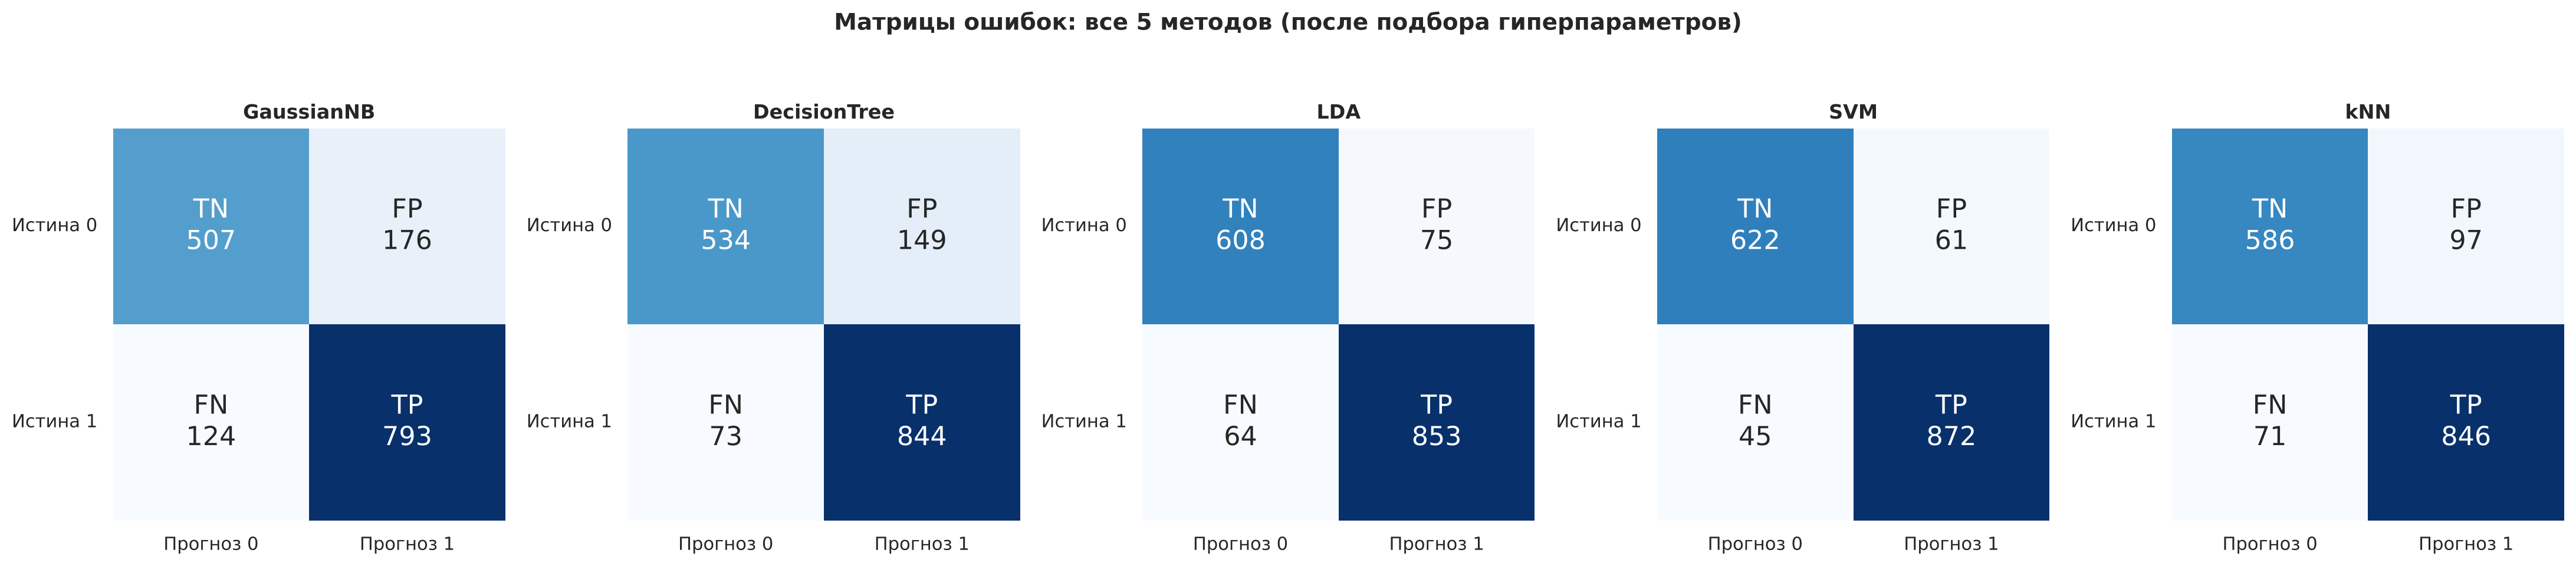

In [19]:
plot_confusions(best_models, 'Матрицы ошибок: все 5 методов (после подбора гиперпараметров)', 'Blues')

Те же матрицы для моделей после GridSearch. У дерева число пропусков FN сократилось вдвое (145 → 73) при почти том же FP (142 → 149); у kNN уменьшились оба вида ошибок (FP 113 → 97, FN 98 → 71); у SVM стало меньше ложных тревог (FP 68 → 61) при FN 44 → 45.

### 4.2. Исследование влияния отдельных параметров

Для каждого значения параметра запускается 5-фолдовая кросс-валидация на обучающей выборке и строятся две кривые: средняя F1 на обучающих фолдах (train) и на валидационных (validation). Расхождение кривых — признак переобучения; низкие значения обеих — недообучения. Закрашенная область — ± стандартное отклонение по фолдам, красная линия — лучшее значение по валидации.

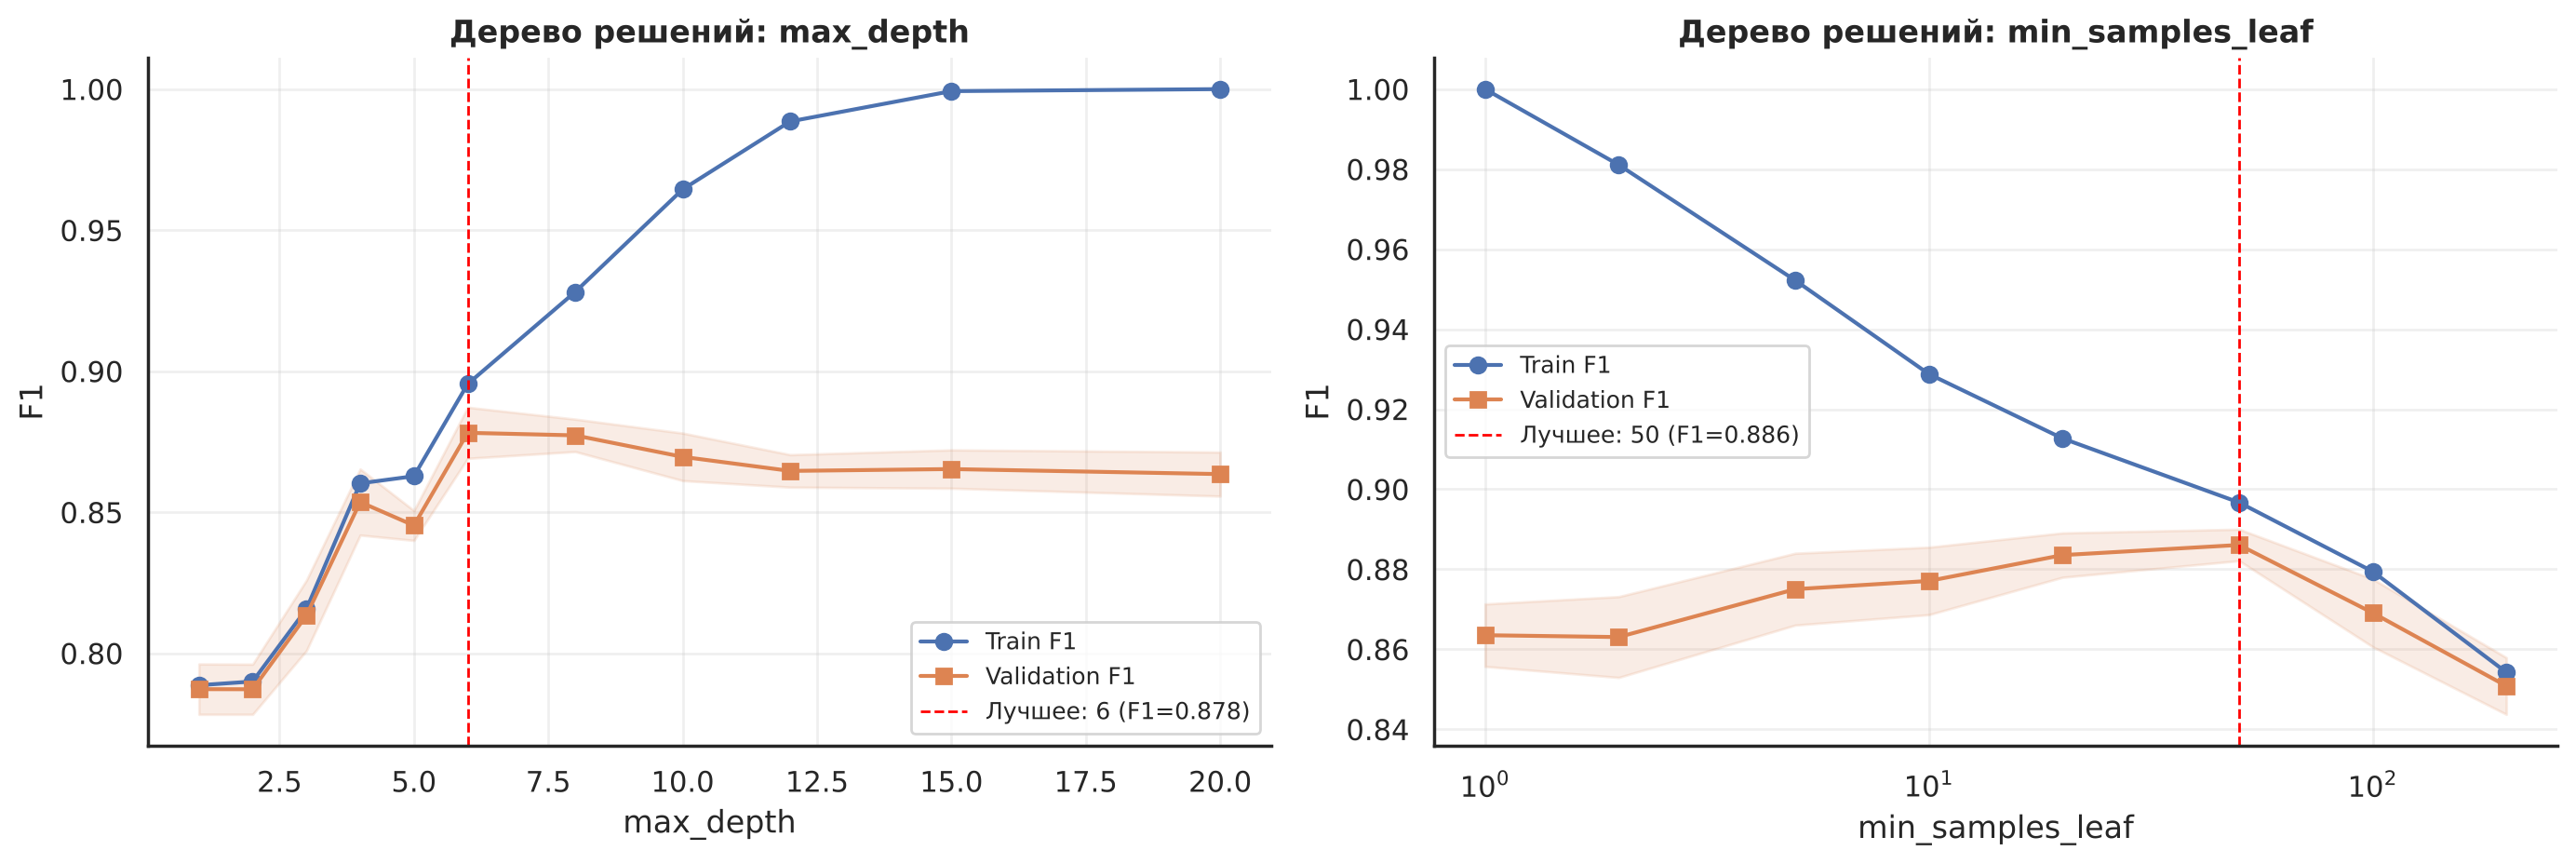

 max_depth  train_f1  val_f1
         1    0.7887  0.7873
         2    0.7900  0.7872
         3    0.8157  0.8134
         4    0.8602  0.8536
         5    0.8628  0.8453
         6    0.8954  0.8781
         8    0.9281  0.8772
        10    0.9645  0.8696
        12    0.9885  0.8646
        15    0.9993  0.8653
        20    1.0000  0.8635

 min_samples_leaf  train_f1  val_f1
                1    1.0000  0.8635
                2    0.9811  0.8630
                5    0.9522  0.8750
               10    0.9288  0.8771
               20    0.9127  0.8835
               50    0.8967  0.8861
              100    0.8794  0.8691
              200    0.8542  0.8508


In [20]:
def plot_param_influence(estimator, param_name, param_range, title, ax, logx=False, labels=None):
    """Кривая валидации: F1 на train- и validation-фолдах при изменении одного гиперпараметра."""
    tr, va = validation_curve(estimator, X_train_prep, y_train, param_name=param_name,
                              param_range=param_range, cv=cv, scoring='f1', n_jobs=-1)
    tr_m, va_m, va_s = tr.mean(axis=1), va.mean(axis=1), va.std(axis=1)
    xs = np.arange(len(param_range)) if labels else np.array(param_range, dtype=float)
    ax.plot(xs, tr_m, marker='o', label='Train F1')
    ax.plot(xs, va_m, marker='s', label='Validation F1')
    ax.fill_between(xs, va_m - va_s, va_m + va_s, alpha=0.15, color='C1')
    best = int(np.argmax(va_m))
    ax.axvline(xs[best], color='red', ls='--', lw=1,
               label=f'Лучшее: {labels[best] if labels else param_range[best]} (F1={va_m[best]:.3f})')
    if labels: ax.set_xticks(xs); ax.set_xticklabels(labels)
    if logx: ax.set_xscale('log')
    ax.set_xlabel(param_name); ax.set_ylabel('F1')
    ax.set_title(title, fontweight='bold'); ax.grid(alpha=0.3); ax.legend(fontsize=9)
    return pd.DataFrame({param_name: labels if labels else list(param_range),
                         'train_f1': tr_m.round(4), 'val_f1': va_m.round(4)})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
t1 = plot_param_influence(DecisionTreeClassifier(random_state=SEED), 'max_depth',
                          [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20], 'Дерево решений: max_depth', axes[0])
t2 = plot_param_influence(DecisionTreeClassifier(random_state=SEED), 'min_samples_leaf',
                          [1, 2, 5, 10, 20, 50, 100, 200], 'Дерево решений: min_samples_leaf', axes[1], logx=True)
plt.tight_layout(); plt.show()
print(t1.to_string(index=False)); print(); print(t2.to_string(index=False))

**Дерево решений.**

- `max_depth`: при глубине 1–2 дерево недообучено (F1 ≈ 0.79 и на train, и на validation). До глубины 6 обе кривые растут вместе, максимум валидации — 0.878 при глубине 6. Дальше train F1 уходит к 1.0 (при глубине 20 дерево запоминает выборку), а validation F1 снижается до 0.864 — классическое переобучение и иллюстрация компромисса смещение–разброс.
- `min_samples_leaf`: обратная картина. При 1 объекте в листе — полное запоминание (train 1.0, validation 0.864); с ростом минимального размера листа кривые сближаются, максимум валидации — 0.886 при 50 объектах; при 200 дерево уже слишком грубое (0.851).

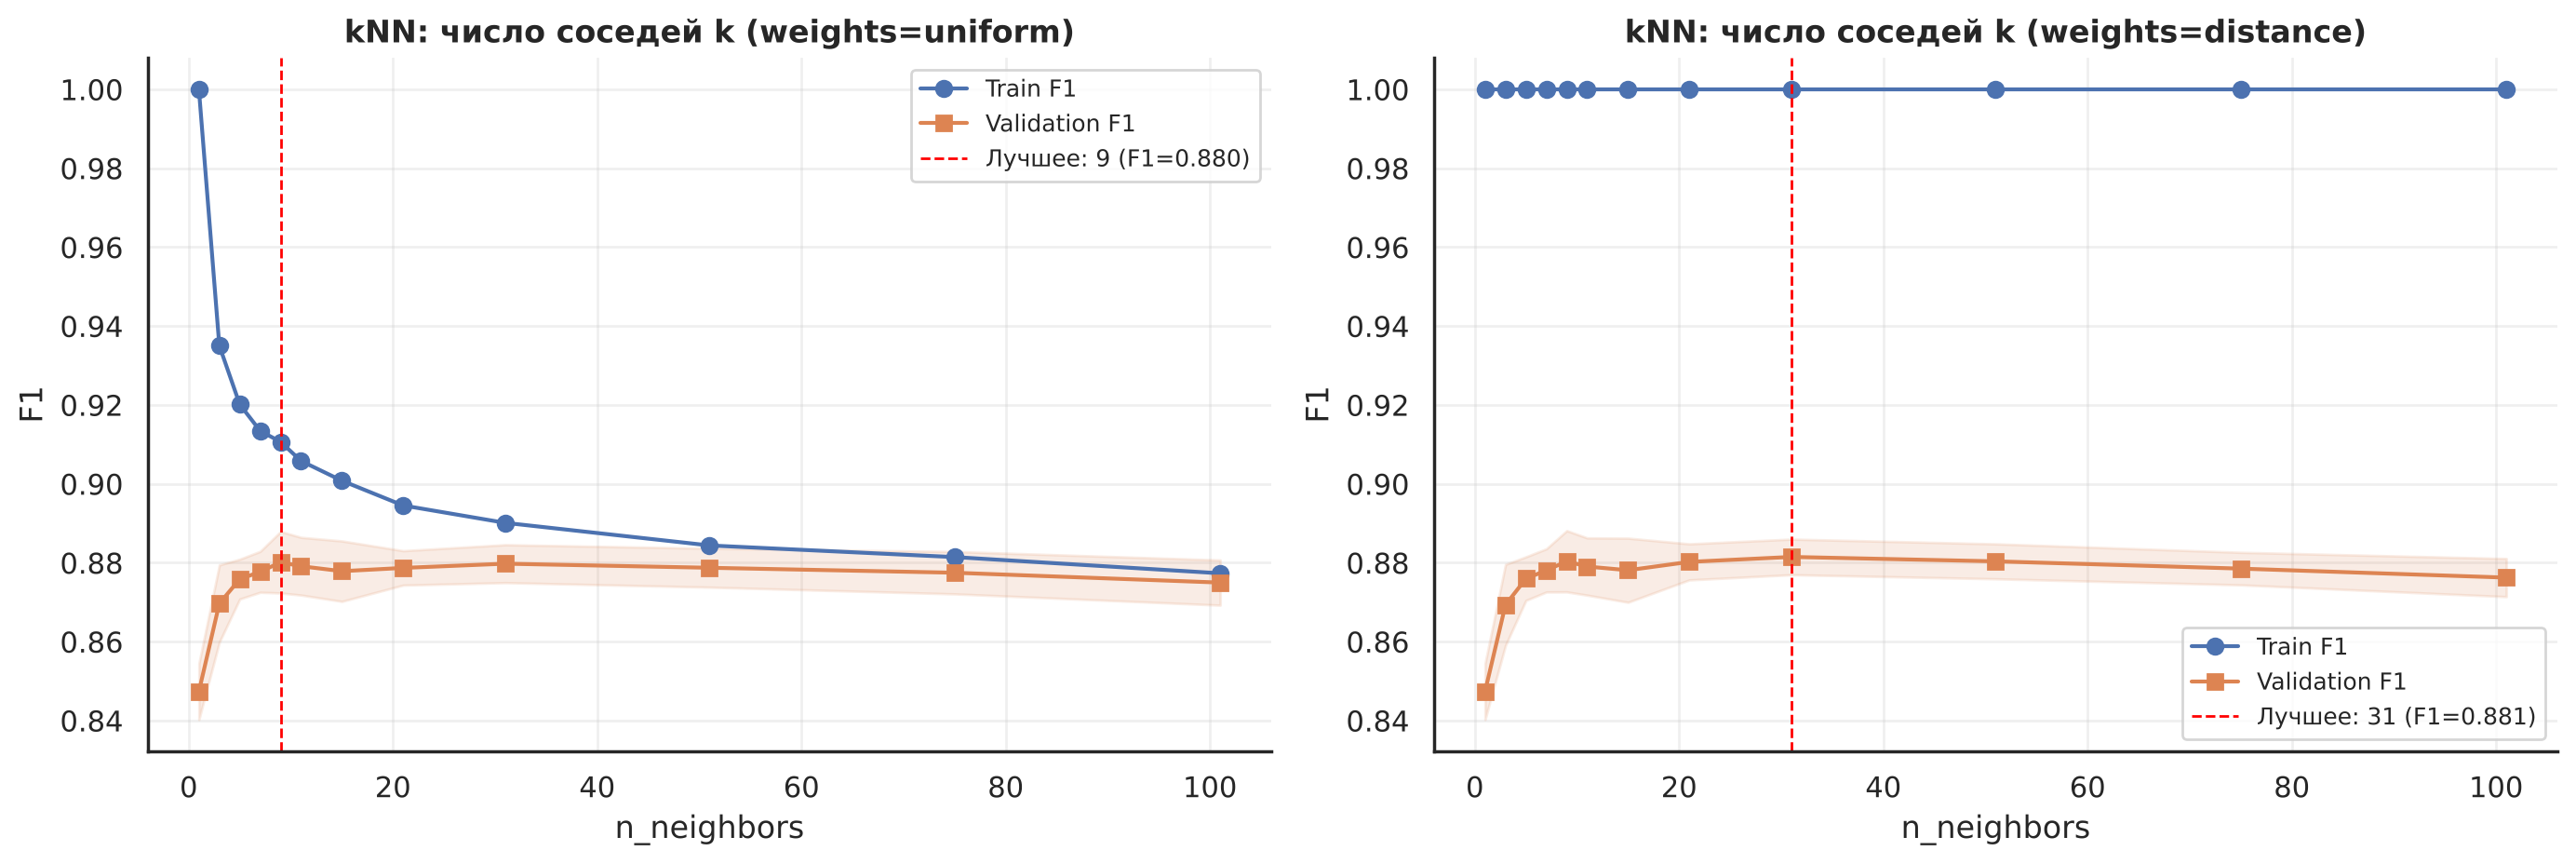

 n_neighbors  train_f1_uniform  val_f1_uniform  train_f1_distance  val_f1_distance
           1            1.0000          0.8474                1.0           0.8474
           3            0.9350          0.8697                1.0           0.8693
           5            0.9201          0.8759                1.0           0.8760
           7            0.9134          0.8777                1.0           0.8781
           9            0.9106          0.8801                1.0           0.8804
          11            0.9058          0.8791                1.0           0.8790
          15            0.9008          0.8779                1.0           0.8781
          21            0.8945          0.8787                1.0           0.8802
          31            0.8901          0.8798                1.0           0.8815
          51            0.8844          0.8787                1.0           0.8804
          75            0.8814          0.8775                1.0           0.8785
    

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101]
t1 = plot_param_influence(KNeighborsClassifier(weights='uniform'), 'n_neighbors', ks,
                          'kNN: число соседей k (weights=uniform)', axes[0])
t2 = plot_param_influence(KNeighborsClassifier(weights='distance'), 'n_neighbors', ks,
                          'kNN: число соседей k (weights=distance)', axes[1])
plt.tight_layout(); plt.show()
print(t1.merge(t2, on='n_neighbors', suffixes=('_uniform', '_distance')).to_string(index=False))

**kNN.**

- При `k = 1` модель переобучена: train F1 = 1.0, validation = 0.847. С ростом k до 9 качество на валидации растёт до 0.880, после чего выходит на плато 0.875–0.882 вплоть до k = 101: метод мало чувствителен к точному значению k, если оно не слишком мало.
- `weights = distance` даёт чуть лучший результат при больших k (0.8815 против 0.8798 при k = 31), так как далёкие соседи получают меньший вес. Train F1 = 1.0 при этом не говорит о переобучении: каждый объект обучающей выборки является собственным соседом на нулевом расстоянии.

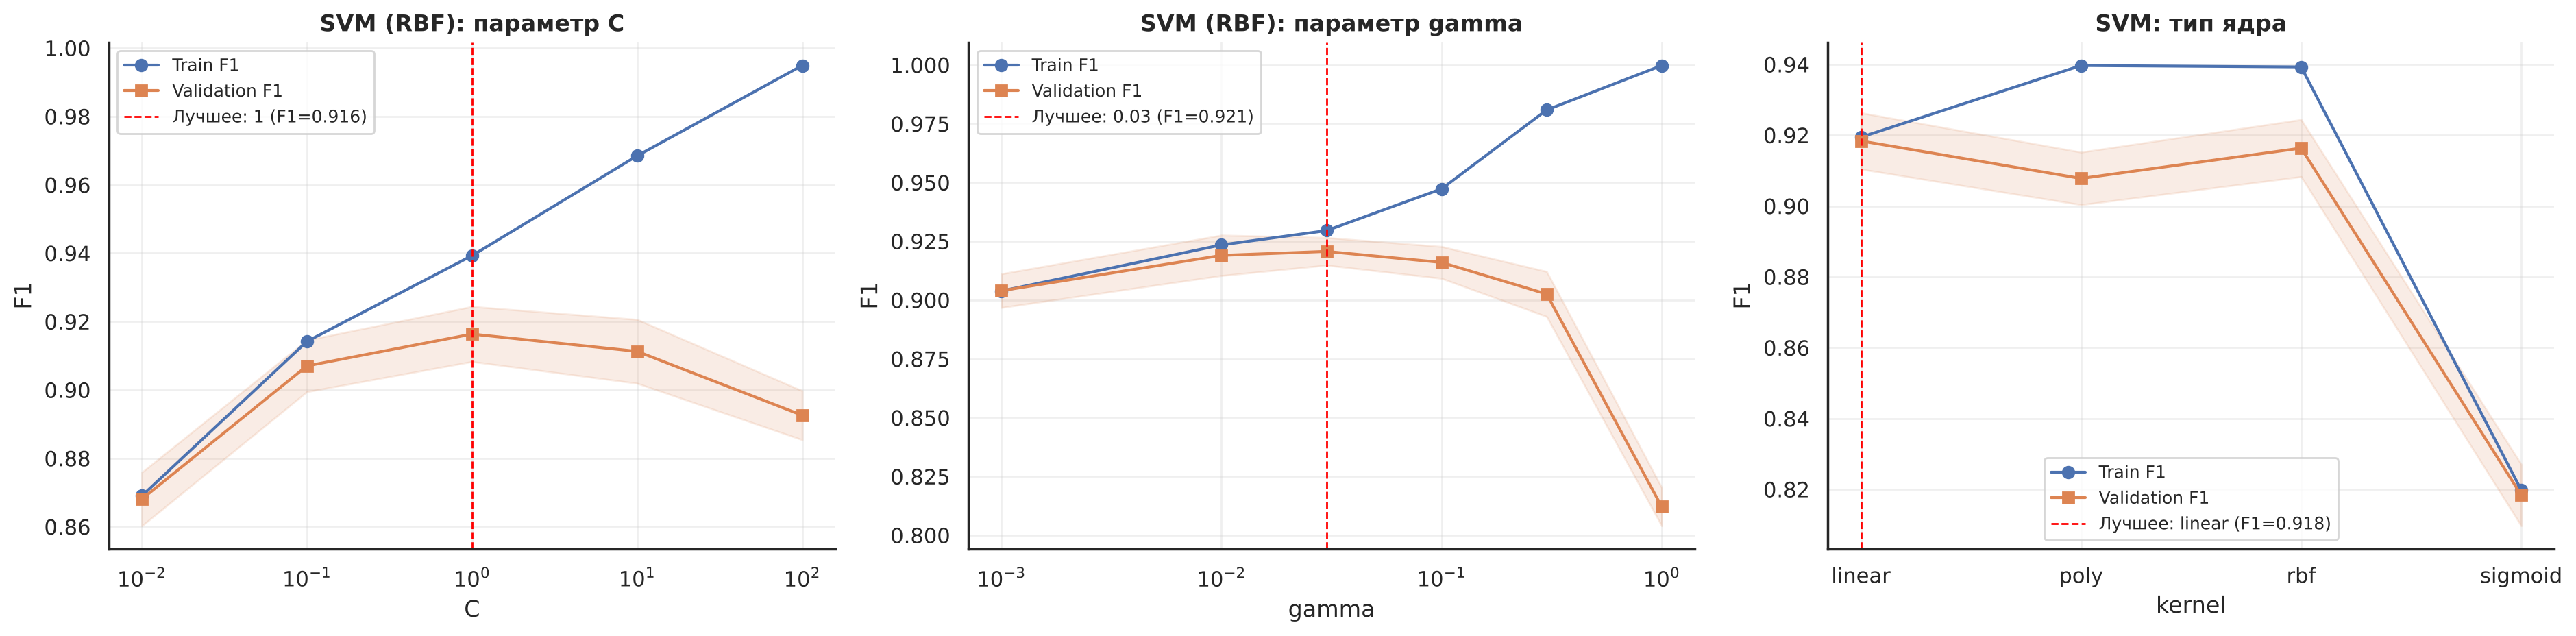

     C  train_f1  val_f1
  0.01    0.8690  0.8681
  0.10    0.9142  0.9070
  1.00    0.9393  0.9163
 10.00    0.9685  0.9113
100.00    0.9949  0.8926

 gamma  train_f1  val_f1
 0.001    0.9039  0.9040
 0.010    0.9234  0.9190
 0.030    0.9295  0.9207
 0.100    0.9473  0.9160
 0.300    0.9808  0.9026
 1.000    0.9997  0.8121

 kernel  train_f1  val_f1
 linear    0.9194  0.9184
   poly    0.9397  0.9078
    rbf    0.9393  0.9163
sigmoid    0.8198  0.8184


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
t1 = plot_param_influence(SVC(kernel='rbf', gamma='scale', random_state=SEED), 'C',
                          [0.01, 0.1, 1, 10, 100], 'SVM (RBF): параметр C', axes[0], logx=True)
t2 = plot_param_influence(SVC(kernel='rbf', C=1.0, random_state=SEED), 'gamma',
                          [0.001, 0.01, 0.03, 0.1, 0.3, 1.0], 'SVM (RBF): параметр gamma', axes[1], logx=True)
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
t3 = plot_param_influence(SVC(C=1.0, gamma='scale', random_state=SEED), 'kernel',
                          kernels, 'SVM: тип ядра', axes[2], labels=kernels)
plt.tight_layout(); plt.show()
print(t1.to_string(index=False)); print(); print(t2.to_string(index=False)); print(); print(t3.to_string(index=False))

**SVM.**

- `C` (RBF-ядро): при C = 0.01 модель недообучена (0.868), оптимум на валидации — C = 1 (0.916); при C = 100 train F1 достигает 0.995, а validation падает до 0.893 — переобучение.
- `gamma` (при C = 1): оптимум — 0.03 (0.921). При gamma = 1 каждая опорная точка влияет только на ближайшую окрестность: train F1 ≈ 1.0, validation — 0.812, самое сильное переобучение среди всех опытов.
- Параметры взаимосвязаны: в сетке лучшей оказалась пара C = 10, gamma = 0.01 (0.922) — более «широкое» ядро допускает больший штраф C.
- Ядро: линейное (0.918) и RBF (0.916) практически равны, полиномиальное немного хуже (0.908), сигмоидное существенно хуже (0.818). То, что линейное ядро не уступает RBF, говорит о почти линейной разделимости классов — это согласуется с высоким результатом LDA.

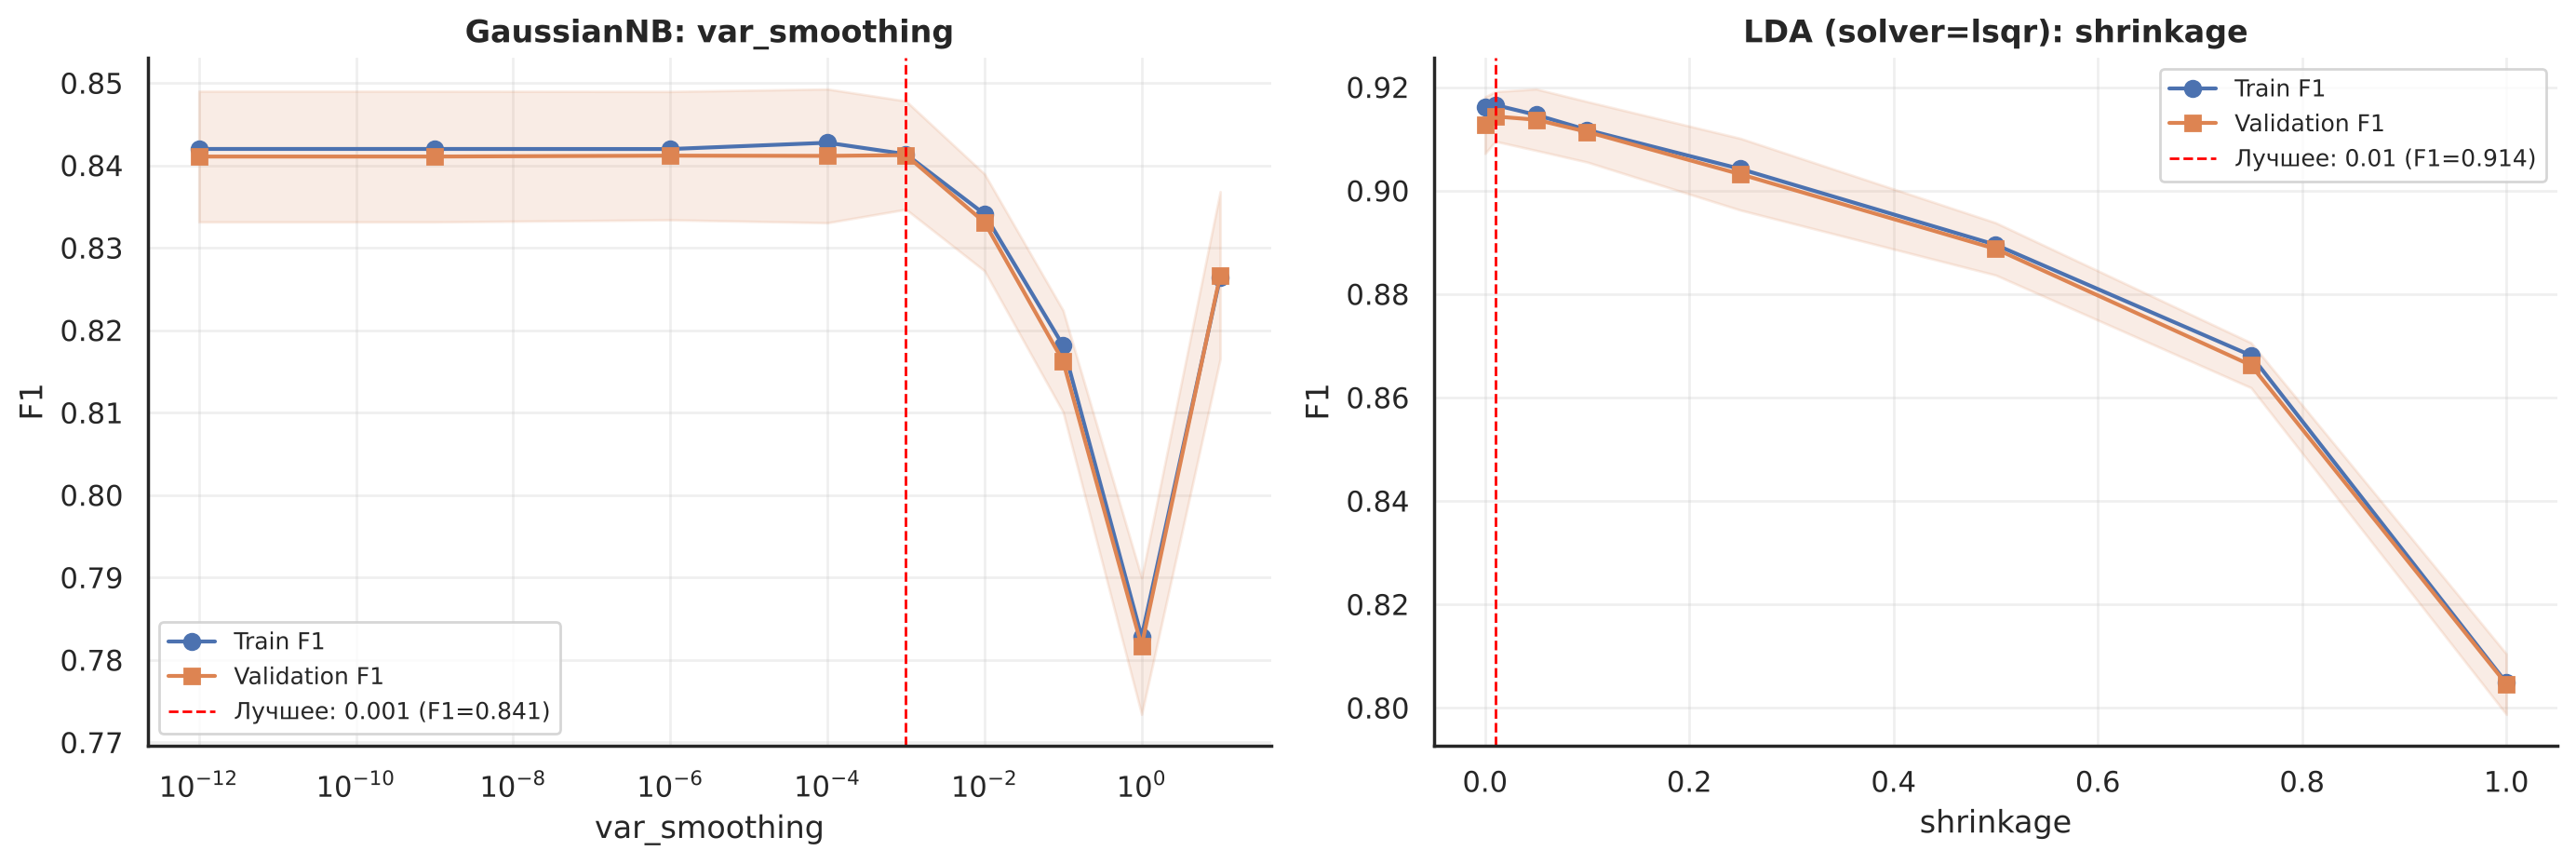

 var_smoothing  train_f1  val_f1
  1.000000e-12    0.8420  0.8411
  1.000000e-09    0.8420  0.8411
  1.000000e-06    0.8420  0.8412
  1.000000e-04    0.8427  0.8411
  1.000000e-03    0.8413  0.8412
  1.000000e-02    0.8341  0.8331
  1.000000e-01    0.8181  0.8162
  1.000000e+00    0.7828  0.7817
  1.000000e+01    0.8264  0.8267

 shrinkage  train_f1  val_f1
      0.00    0.9161  0.9126
      0.01    0.9165  0.9143
      0.05    0.9146  0.9137
      0.10    0.9117  0.9113
      0.25    0.9042  0.9032
      0.50    0.8895  0.8887
      0.75    0.8681  0.8662
      1.00    0.8048  0.8046


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
t1 = plot_param_influence(GaussianNB(), 'var_smoothing',
                          [1e-12, 1e-9, 1e-6, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0],
                          'GaussianNB: var_smoothing', axes[0], logx=True)
t2 = plot_param_influence(LinearDiscriminantAnalysis(solver='lsqr'), 'shrinkage',
                          [0.0, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0],
                          'LDA (solver=lsqr): shrinkage', axes[1])
plt.tight_layout(); plt.show()
print(t1.to_string(index=False)); print(); print(t2.to_string(index=False))

**GaussianNB и LDA.**

- `var_smoothing`: в диапазоне 1e-12…1e-3 качество не меняется (F1 ≈ 0.841) — данные стандартизованы, нулевых дисперсий нет, стабилизация не нужна. При значениях от 0.01 сглаживание начинает искажать распределения, и F1 падает до 0.782 при 1.0.
- `shrinkage` в LDA: небольшая регуляризация (0.01) даёт прирост в четвёртом знаке (0.9143 против 0.9126), дальнейшее увеличение монотонно ухудшает качество до 0.805 при shrinkage = 1. При shrinkage = 1 ковариационная матрица заменяется диагональной, то есть корреляции между признаками игнорируются, как в наивном Байесе, — и качество опускается до его уровня. При 6400 объектах и 26 признаках ковариация оценивается надёжно, регуляризация не требуется.

## 5. Нейронная сеть на TensorFlow

### 5.1. Архитектура

In [24]:
# Валидационная выборка для мониторинга обучения выделяется из train (тест не трогаем)
X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train_prep, y_train.values, test_size=0.2, random_state=SEED, stratify=y_train
)
input_dim = X_nn_train.shape[1]
print('NN train:', X_nn_train.shape, '| NN val:', X_nn_val.shape, '| input_dim =', input_dim)

def build_nn(hidden=(32, 16), activation='relu', lr=1e-3, dropout=0.2):
    model = keras.Sequential([keras.Input(shape=(input_dim,))])
    for i, units in enumerate(hidden):
        model.add(layers.Dense(units, activation=activation))
        if i == 0 and dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

keras.utils.set_random_seed(SEED)
build_nn().summary()

NN train: (5120, 26) | NN val: (1280, 26) | input_dim = 26


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,409 (5.50 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 0 (0.00 B)

Реализована полносвязная нейронная сеть (многослойный перцептрон) для бинарной классификации. Базовая архитектура:

- **входной слой** — 26 признаков (размерность данных после стандартизации и One-Hot Encoding);
- **скрытый слой 1** (Dense) — 32 нейрона, функция активации ReLU;
- **Dropout(0.2)** — на каждом шаге обучения случайно отключается 20% нейронов, регуляризация против переобучения;
- **скрытый слой 2** (Dense) — 16 нейронов, ReLU;
- **выходной слой** (Dense) — 1 нейрон с сигмоидой, выдаёт вероятность класса 1.

Всего 1409 обучаемых параметров. Функция потерь — `binary_crossentropy` (стандарт для бинарной классификации), оптимизатор — Adam со скоростью обучения 0.001, отслеживаемая метрика — accuracy.

Из обучающей выборки дополнительно выделено 20% (1280 объектов) под валидацию: по ней отслеживается ход обучения и сравниваются конфигурации. Тестовая выборка в экспериментах не используется.

In [25]:
LOG_ROOT = os.path.join('logs', 'fit')
shutil.rmtree('logs', ignore_errors=True)     # чистим логи прошлых запусков
os.makedirs(LOG_ROOT, exist_ok=True)

DEFAULT_BATCH_SIZE = 32
DEFAULT_EPOCHS = 40
nn_runs = {}                                  # имя -> dict(history, параметры, метрики)

def run_experiment(name, hidden=(32, 16), activation='relu', lr=1e-3,
                   batch_size=DEFAULT_BATCH_SIZE, epochs=DEFAULT_EPOCHS, histogram_freq=0):
    keras.utils.set_random_seed(SEED)         # одинаковая инициализация весов во всех опытах
    model = build_nn(hidden, activation, lr)
    tb = keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_ROOT, name), histogram_freq=histogram_freq)
    t0 = time.time()
    hist = model.fit(X_nn_train, y_nn_train, validation_data=(X_nn_val, y_nn_val),
                     batch_size=batch_size, epochs=epochs, callbacks=[tb], verbose=0)
    proba = model.predict(X_nn_val, verbose=0).ravel()
    nn_runs[name] = dict(
        history=hist.history, hidden=hidden, activation=activation, lr=lr,
        batch_size=batch_size, epochs=epochs, params=model.count_params(),
        train_acc=hist.history['accuracy'][-1], val_acc=hist.history['val_accuracy'][-1],
        val_loss=hist.history['val_loss'][-1], min_val_loss=min(hist.history['val_loss']),
        best_epoch=int(np.argmin(hist.history['val_loss'])) + 1,
        val_f1=f1_score(y_nn_val, (proba >= 0.5).astype(int)), time=time.time() - t0)
    r = nn_runs[name]
    print(f"{name:28s} val_acc={r['val_acc']:.4f} val_f1={r['val_f1']:.4f} "
          f"val_loss={r['val_loss']:.4f} (min {r['min_val_loss']:.4f} на эпохе {r['best_epoch']}) {r['time']:.0f} c")
    return model

def runs_table(names):
    cols = ['hidden', 'activation', 'lr', 'batch_size', 'epochs', 'params',
            'train_acc', 'val_acc', 'val_f1', 'val_loss', 'min_val_loss', 'best_epoch', 'time']
    return pd.DataFrame({n: {c: nn_runs[n][c] for c in cols} for n in names}).T

def plot_runs(names, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for n in names:
        h = nn_runs[n]['history']
        axes[0].plot(h['val_loss'], lw=2, label=n)
        axes[1].plot(h['val_accuracy'], lw=2, label=n)
    axes[0].set_title(f'{title}: validation loss', fontweight='bold')
    axes[1].set_title(f'{title}: validation accuracy', fontweight='bold')
    for ax, yl in zip(axes, ['Loss', 'Accuracy']):
        ax.set_xlabel('Эпоха'); ax.set_ylabel(yl); ax.grid(alpha=0.3); ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()

Вспомогательные функции для экспериментов. `run_experiment` обучает сеть с заданными гиперпараметрами и записывает ход обучения в отдельную папку `logs/fit/<имя_эксперимента>` через колбэк `TensorBoard` — каждый эксперимент виден в TensorBoard как отдельный запуск. Перед каждым опытом seed сбрасывается, поэтому сети стартуют с одинаковой инициализации и различия объясняются только изменённым гиперпараметром. В каждом эксперименте меняется один параметр относительно базовой конфигурации (32-16, ReLU, lr = 0.001, batch = 32, 40 эпох).

--- Эксперимент 1: базовая модель 32-16, ReLU, Adam(1e-3), batch=32, 100 эпох ---


base_32-16_relu_100ep        val_acc=0.9086 val_f1=0.9194 val_loss=0.2079 (min 0.1880 на эпохе 22) 48 c


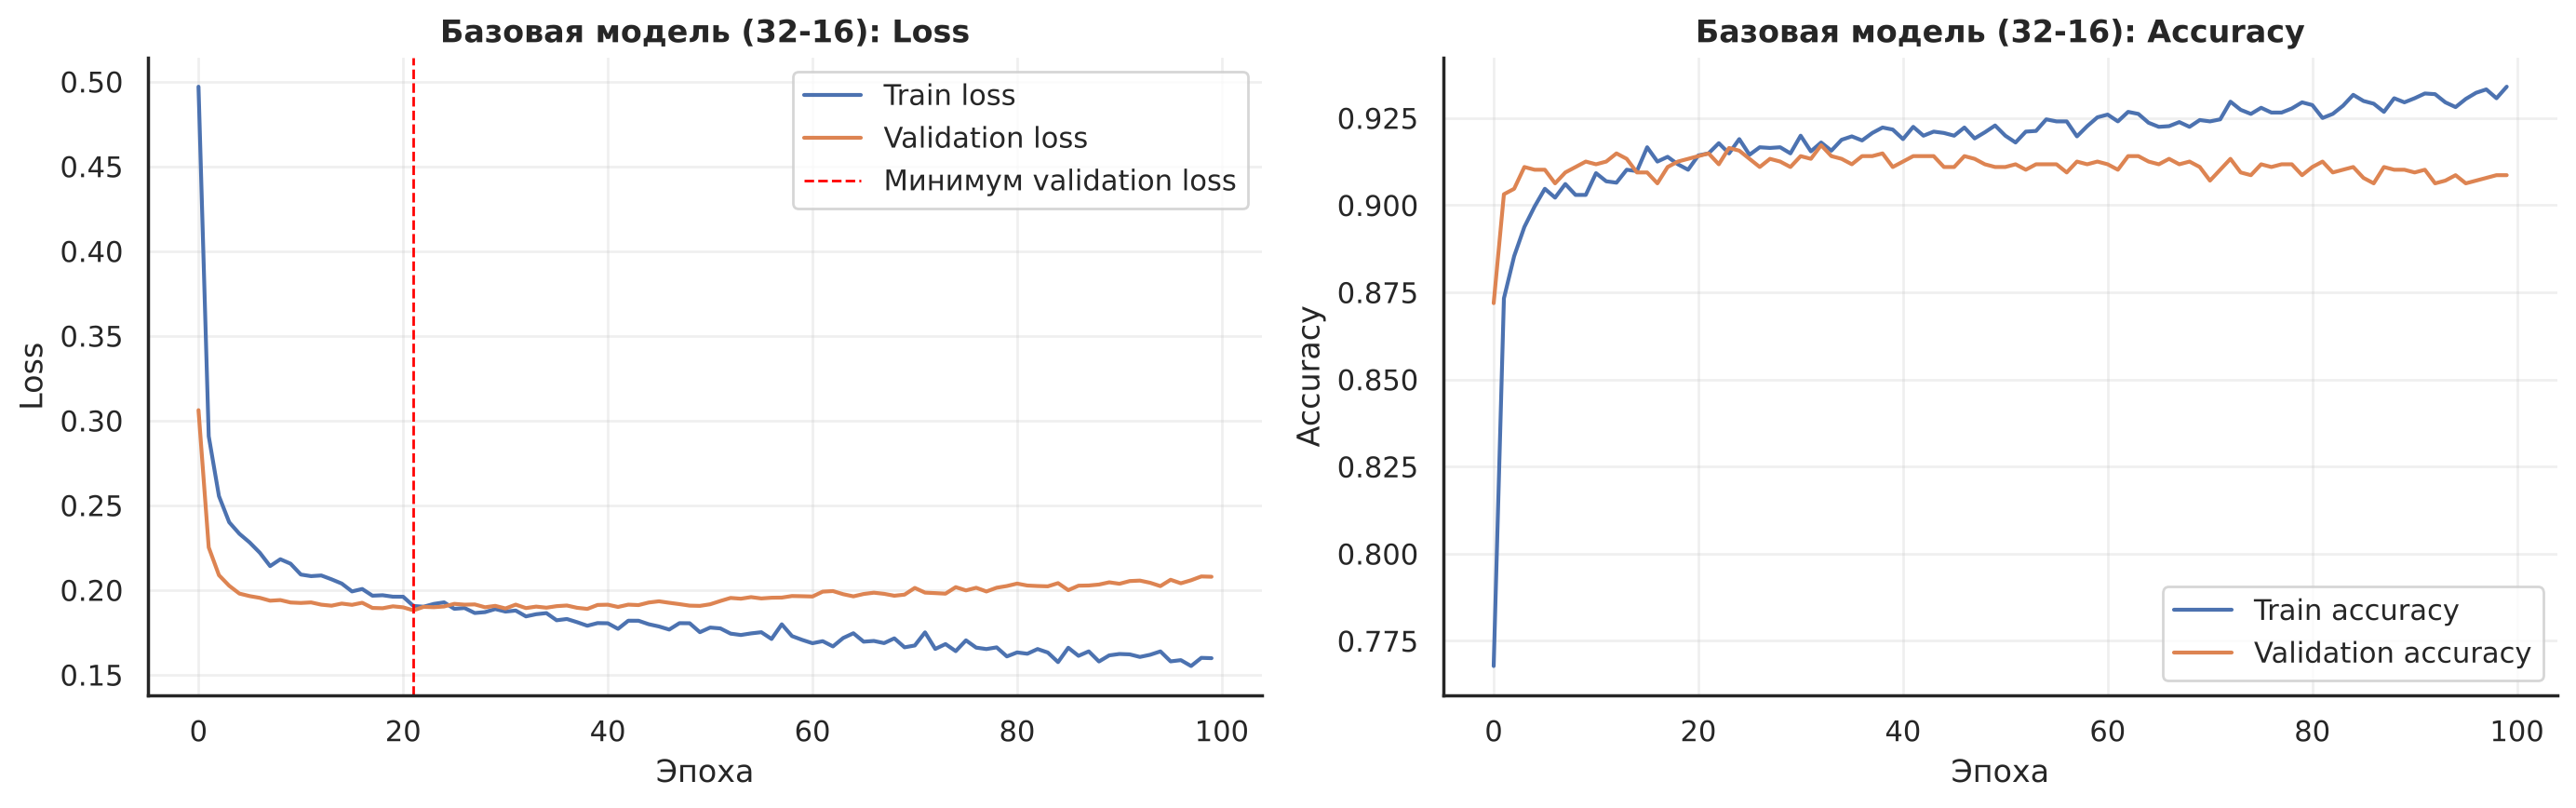


Влияние числа эпох (значения из истории обучения базовой модели):
        loss  val_loss  accuracy  val_accuracy
эпох                                          
1     0.4970    0.3062    0.7678        0.8719
5     0.2332    0.1979    0.8996        0.9102
10    0.2155    0.1927    0.9029        0.9125
20    0.1961    0.1904    0.9102        0.9133
40    0.1805    0.1912    0.9217        0.9109
60    0.1706    0.1964    0.9252        0.9125
80    0.1608    0.2024    0.9295        0.9086
100   0.1598    0.2079    0.9340        0.9086


In [26]:
print('--- Эксперимент 1: базовая модель 32-16, ReLU, Adam(1e-3), batch=32, 100 эпох ---')
model_base = run_experiment('base_32-16_relu_100ep', epochs=100, histogram_freq=1)

h = nn_runs['base_32-16_relu_100ep']['history']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(h['loss'], label='Train loss'); axes[0].plot(h['val_loss'], label='Validation loss')
axes[0].axvline(nn_runs['base_32-16_relu_100ep']['best_epoch'] - 1, color='red', ls='--', lw=1,
                label='Минимум validation loss')
axes[1].plot(h['accuracy'], label='Train accuracy'); axes[1].plot(h['val_accuracy'], label='Validation accuracy')
for ax, t in zip(axes, ['Loss', 'Accuracy']):
    ax.set_title(f'Базовая модель (32-16): {t}', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(t); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

print('\nВлияние числа эпох (значения из истории обучения базовой модели):')
ep_tbl = pd.DataFrame({e: {k: h[k][e - 1] for k in ['loss', 'val_loss', 'accuracy', 'val_accuracy']}
                       for e in [1, 5, 10, 20, 40, 60, 80, 100]}).T
ep_tbl.index.name = 'эпох'
print(ep_tbl.round(4))

### 5.2. Базовая модель и влияние числа эпох

Базовая модель обучалась 100 эпох. По графикам:

- первые ~5 эпох — быстрое обучение: validation loss падает с 0.306 до 0.198, accuracy растёт с 0.872 до 0.910;
- минимум validation loss (0.188) достигается на 22-й эпохе;
- далее train loss продолжает снижаться (0.196 → 0.160), train accuracy растёт до 0.934, а validation loss, наоборот, растёт до 0.208, validation accuracy слегка снижается (0.913 → 0.909). Это переобучение: сеть начинает запоминать обучающую выборку.

Вывод: для этой архитектуры достаточно 20–40 эпох; дальнейшее обучение не улучшает, а ухудшает обобщающую способность. В первые эпохи validation-метрики лучше train-метрик — это эффект Dropout, который действует только при обучении.

--- Эксперимент 2: число слоёв и нейронов ---


arch_16                      val_acc=0.9133 val_f1=0.9238 val_loss=0.1873 (min 0.1873 на эпохе 40) 18 c


arch_32-16                   val_acc=0.9109 val_f1=0.9209 val_loss=0.1912 (min 0.1880 на эпохе 22) 18 c


arch_64-32                   val_acc=0.9086 val_f1=0.9193 val_loss=0.2027 (min 0.1931 на эпохе 6) 19 c


arch_128-64-32               val_acc=0.8930 val_f1=0.9026 val_loss=0.3015 (min 0.2078 на эпохе 1) 19 c


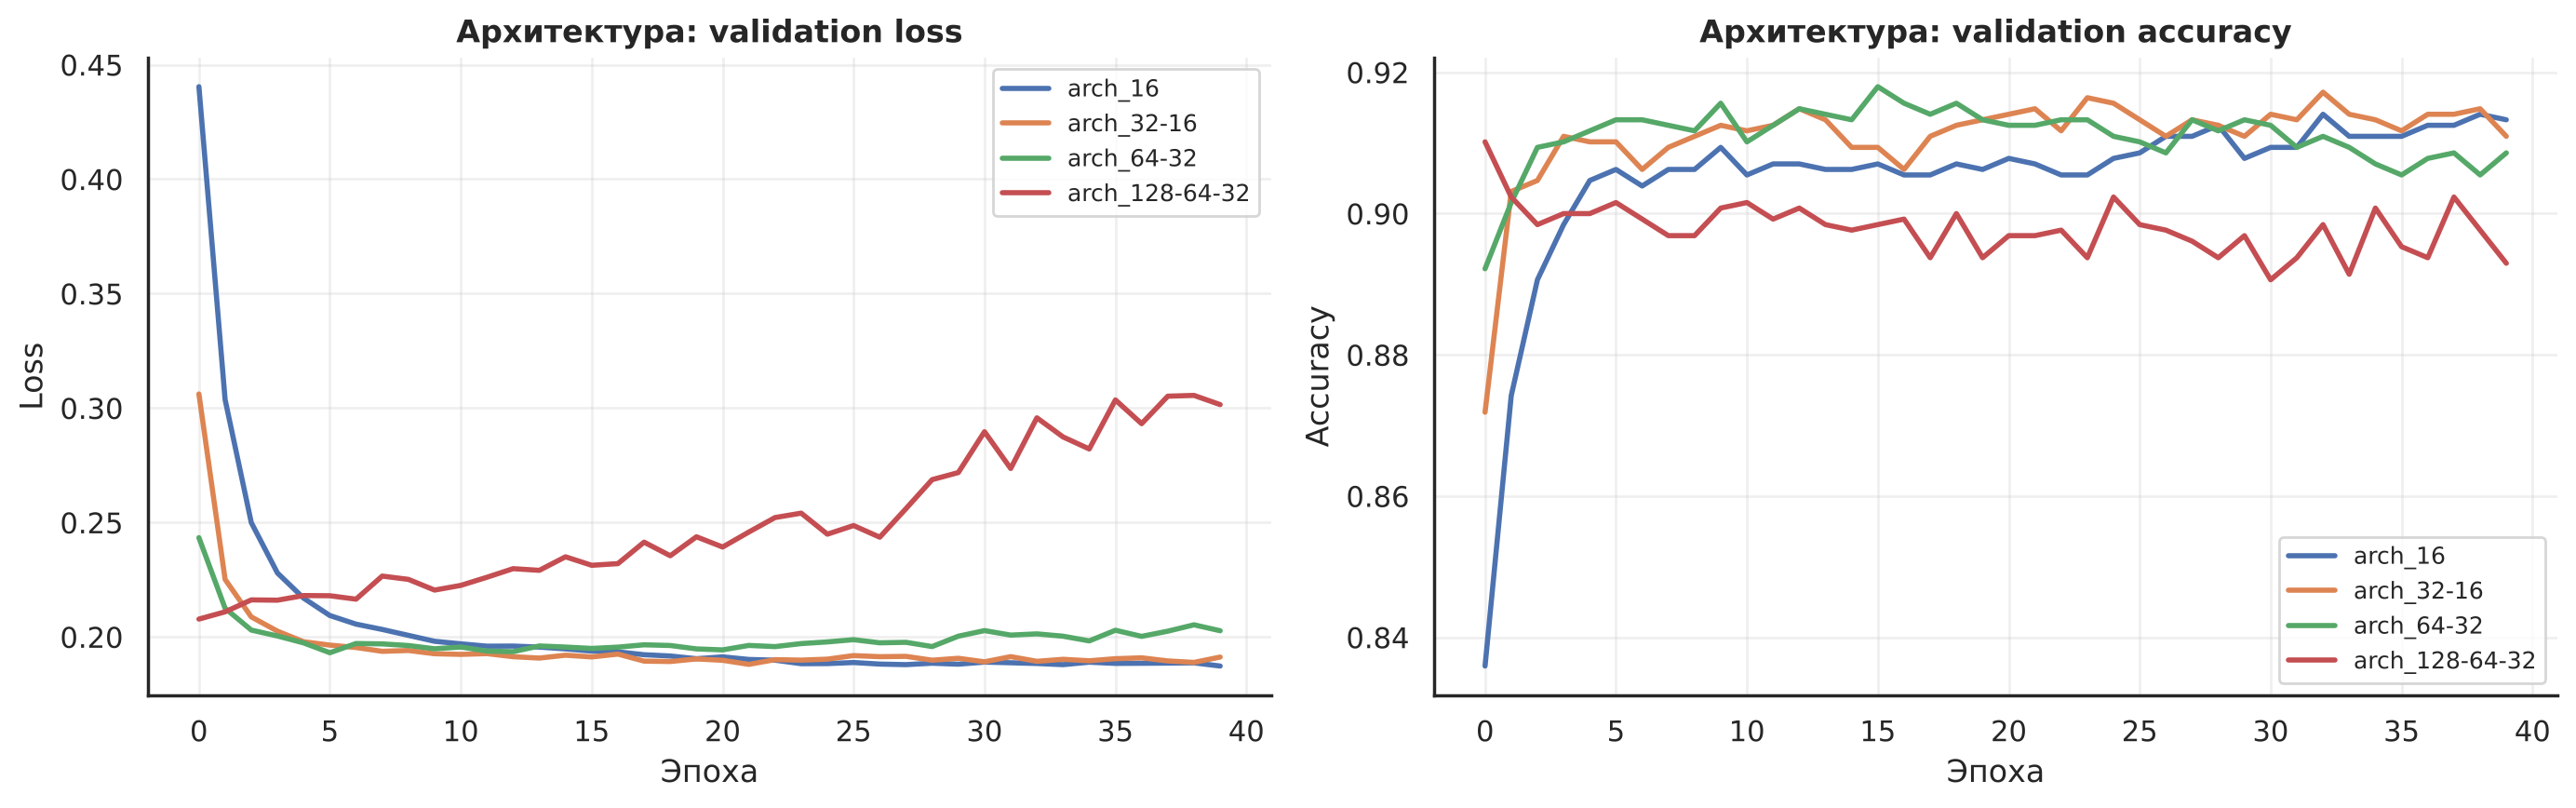

,hidden,params,train_acc,val_acc,val_f1,val_loss,best_epoch
arch_16,"(16,)",449,0.914648,0.913281,0.923816,0.187292,40
arch_32-16,"(32, 16)",1409,0.92168,0.910937,0.920943,0.191212,22
arch_64-32,"(64, 32)",3841,0.930469,0.908594,0.919255,0.202707,6
arch_128-64-32,"(128, 64, 32)",13825,0.948438,0.892969,0.90263,0.301511,1


In [27]:
print('--- Эксперимент 2: число слоёв и нейронов ---')
arch_runs = {'arch_16': (16,), 'arch_32-16': (32, 16), 'arch_64-32': (64, 32), 'arch_128-64-32': (128, 64, 32)}
for name, hidden in arch_runs.items():
    run_experiment(name, hidden=hidden)
plot_runs(list(arch_runs), 'Архитектура')
runs_table(list(arch_runs))[['hidden', 'params', 'train_acc', 'val_acc', 'val_f1', 'val_loss', 'best_epoch']]

### 5.3. Число слоёв и нейронов

- **16** (один скрытый слой, 449 параметров) — обучается медленнее всех, но к 40-й эпохе даёт лучший validation loss в группе (0.187) и accuracy 0.913; минимум loss ещё не пройден.
- **32-16** (1409 параметров) — близкий результат (min loss 0.188 на 22-й эпохе, accuracy 0.911).
- **64-32** (3841 параметр) — минимум loss уже на 6-й эпохе (0.193), затем медленное переобучение.
- **128-64-32** (13 825 параметров) — переобучается с первой же эпохи: train accuracy 0.948, а validation loss растёт с 0.208 до 0.302, validation accuracy — худшая (0.893).

Увеличение сети на этих данных не даёт выигрыша: чем больше параметров, тем раньше и сильнее переобучение. Задача почти линейно разделима, и небольшой сети достаточно.

--- Эксперимент 3: функция активации скрытых слоёв ---


act_tanh                     val_acc=0.9148 val_f1=0.9249 val_loss=0.1933 (min 0.1914 на эпохе 27) 20 c


act_sigmoid                  val_acc=0.9086 val_f1=0.9194 val_loss=0.1920 (min 0.1920 на эпохе 40) 19 c


act_elu                      val_acc=0.9164 val_f1=0.9263 val_loss=0.1867 (min 0.1844 на эпохе 38) 18 c


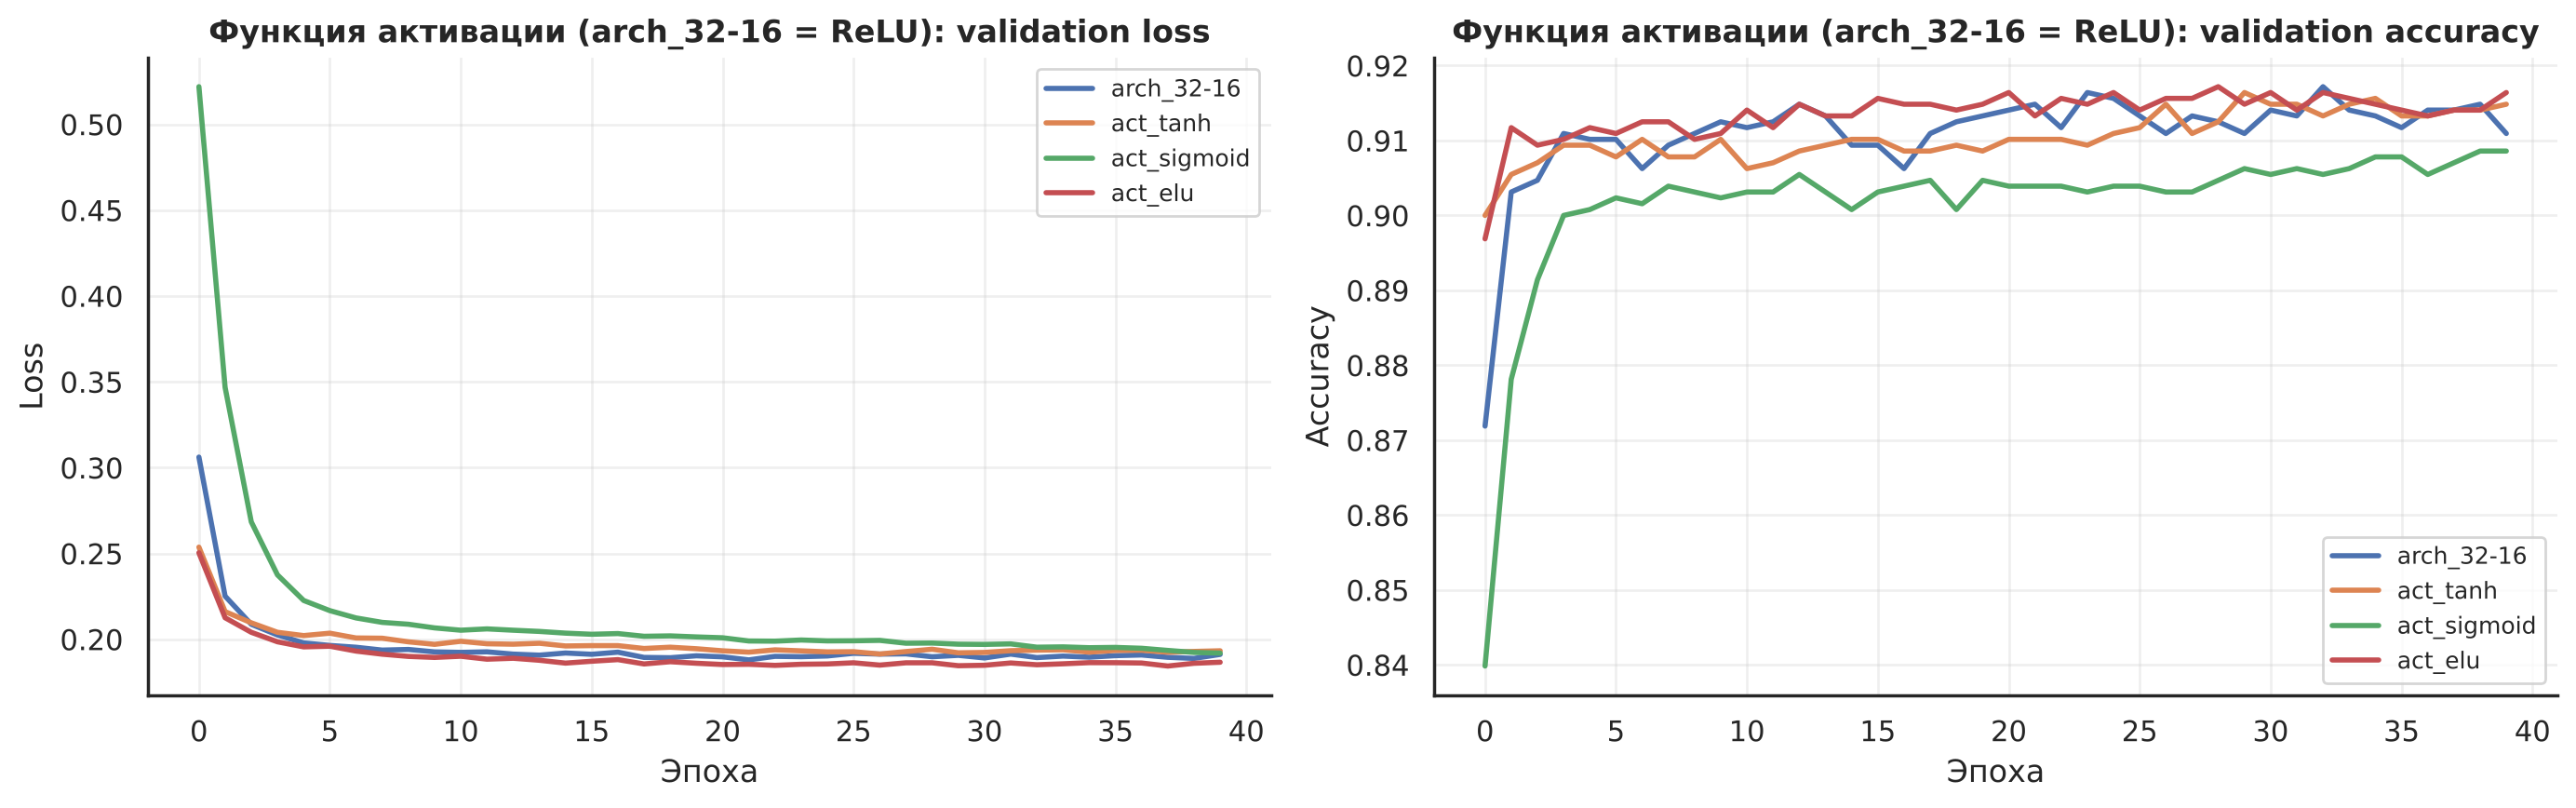

,activation,train_acc,val_acc,val_f1,val_loss,best_epoch
arch_32-16,relu,0.92168,0.910937,0.920943,0.191212,22
act_tanh,tanh,0.913672,0.914844,0.924879,0.193315,27
act_sigmoid,sigmoid,0.903711,0.908594,0.919366,0.191953,40
act_elu,elu,0.916406,0.916406,0.926258,0.186653,38


In [28]:
print('--- Эксперимент 3: функция активации скрытых слоёв ---')
act_runs = ['arch_32-16', 'act_tanh', 'act_sigmoid', 'act_elu']
for act in ['tanh', 'sigmoid', 'elu']:
    run_experiment(f'act_{act}', activation=act)
plot_runs(act_runs, 'Функция активации (arch_32-16 = ReLU)')
runs_table(act_runs)[['activation', 'train_acc', 'val_acc', 'val_f1', 'val_loss', 'best_epoch']]

### 5.4. Функция активации

Различия между функциями активации невелики (validation accuracy 0.909–0.916):

- **ELU** — лучший результат: min validation loss 0.184, accuracy 0.916, F1 0.926;
- **tanh** — accuracy 0.915, loss 0.191;
- **ReLU** — accuracy 0.911, loss 0.188, но минимум достигается раньше всех (22-я эпоха), после чего начинается переобучение;
- **sigmoid** — обучается медленнее всех (минимум loss на последней, 40-й эпохе; train accuracy лишь 0.904): сигмоида насыщается и даёт малые градиенты.

--- Эксперимент 4: размер батча ---


bs_16                        val_acc=0.9047 val_f1=0.9148 val_loss=0.1984 (min 0.1923 на эпохе 15) 32 c


bs_128                       val_acc=0.9156 val_f1=0.9263 val_loss=0.1874 (min 0.1872 на эпохе 36) 7 c


bs_512                       val_acc=0.9117 val_f1=0.9230 val_loss=0.1916 (min 0.1916 на эпохе 40) 5 c


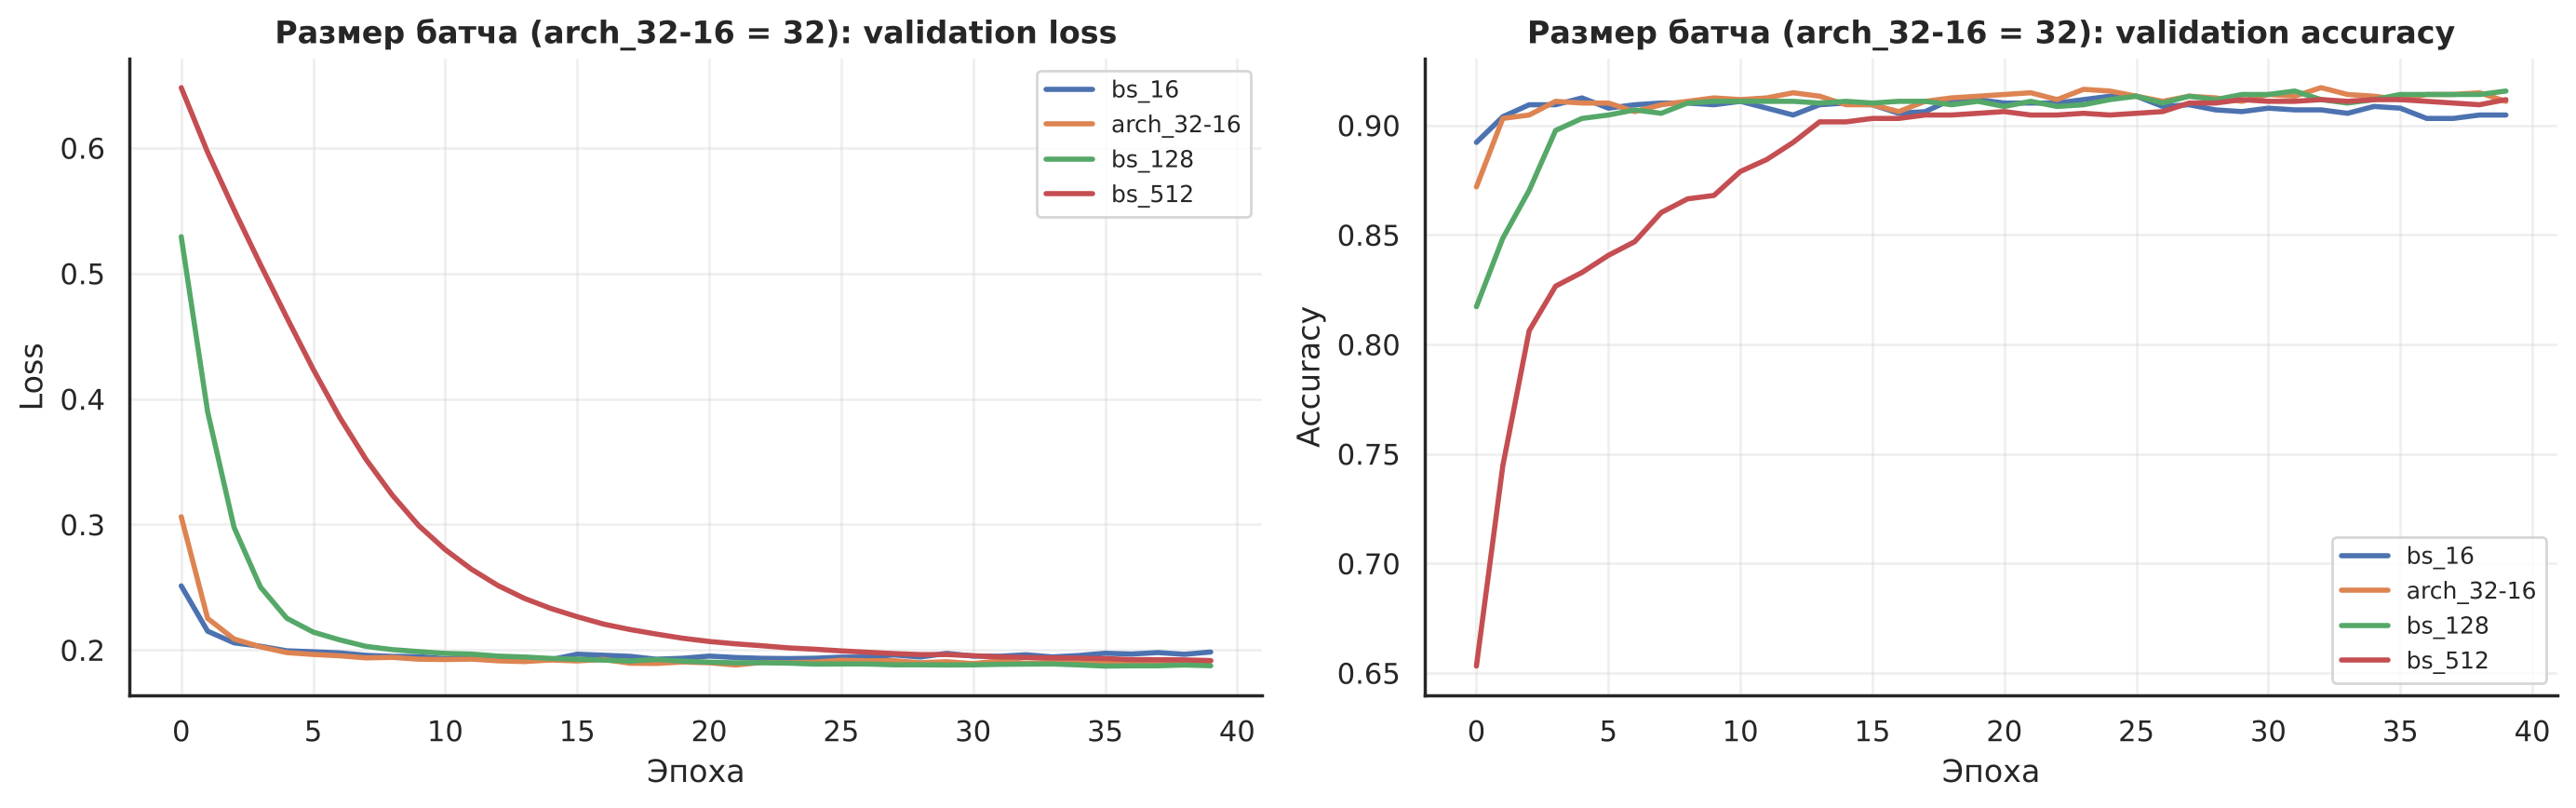

,batch_size,train_acc,val_acc,val_f1,val_loss,best_epoch,time
bs_16,16,0.922656,0.904688,0.914804,0.19841,15,31.725311
arch_32-16,32,0.92168,0.910937,0.920943,0.191212,22,17.831051
bs_128,128,0.913086,0.915625,0.92633,0.187449,36,7.162886
bs_512,512,0.90293,0.911719,0.922972,0.191577,40,4.802938


In [29]:
print('--- Эксперимент 4: размер батча ---')
bs_runs = ['bs_16', 'arch_32-16', 'bs_128', 'bs_512']
for bs in [16, 128, 512]:
    run_experiment(f'bs_{bs}', batch_size=bs)
plot_runs(bs_runs, 'Размер батча (arch_32-16 = 32)')
runs_table(bs_runs)[['batch_size', 'train_acc', 'val_acc', 'val_f1', 'val_loss', 'best_epoch', 'time']]

### 5.5. Размер батча

- **16** — вдвое больше шагов градиентного спуска за эпоху и самое долгое обучение (около 30 с); быстрее всех переобучается (минимум loss на 15-й эпохе), итоговая accuracy худшая — 0.905.
- **32** — около 17 с, accuracy 0.911.
- **128** — лучший компромисс: около 8 с, accuracy 0.916, loss 0.187; обновления реже, но градиент менее шумный.
- **512** — самое быстрое обучение (около 5 с), но всего 10 шагов за эпоху: за 40 эпох сеть не успела сойтись (минимум loss на последней эпохе, train accuracy 0.903).

Малый батч — шумные градиенты и долгое обучение; большой — быстрые эпохи, но требуется больше эпох для сходимости.

--- Эксперимент 5: скорость обучения (learning rate) ---


lr_0.0001                    val_acc=0.9094 val_f1=0.9209 val_loss=0.1984 (min 0.1984 на эпохе 40) 19 c


lr_0.01                      val_acc=0.9031 val_f1=0.9132 val_loss=0.2458 (min 0.2130 на эпохе 5) 19 c


lr_0.1                       val_acc=0.8953 val_f1=0.9115 val_loss=0.2221 (min 0.2062 на эпохе 23) 18 c


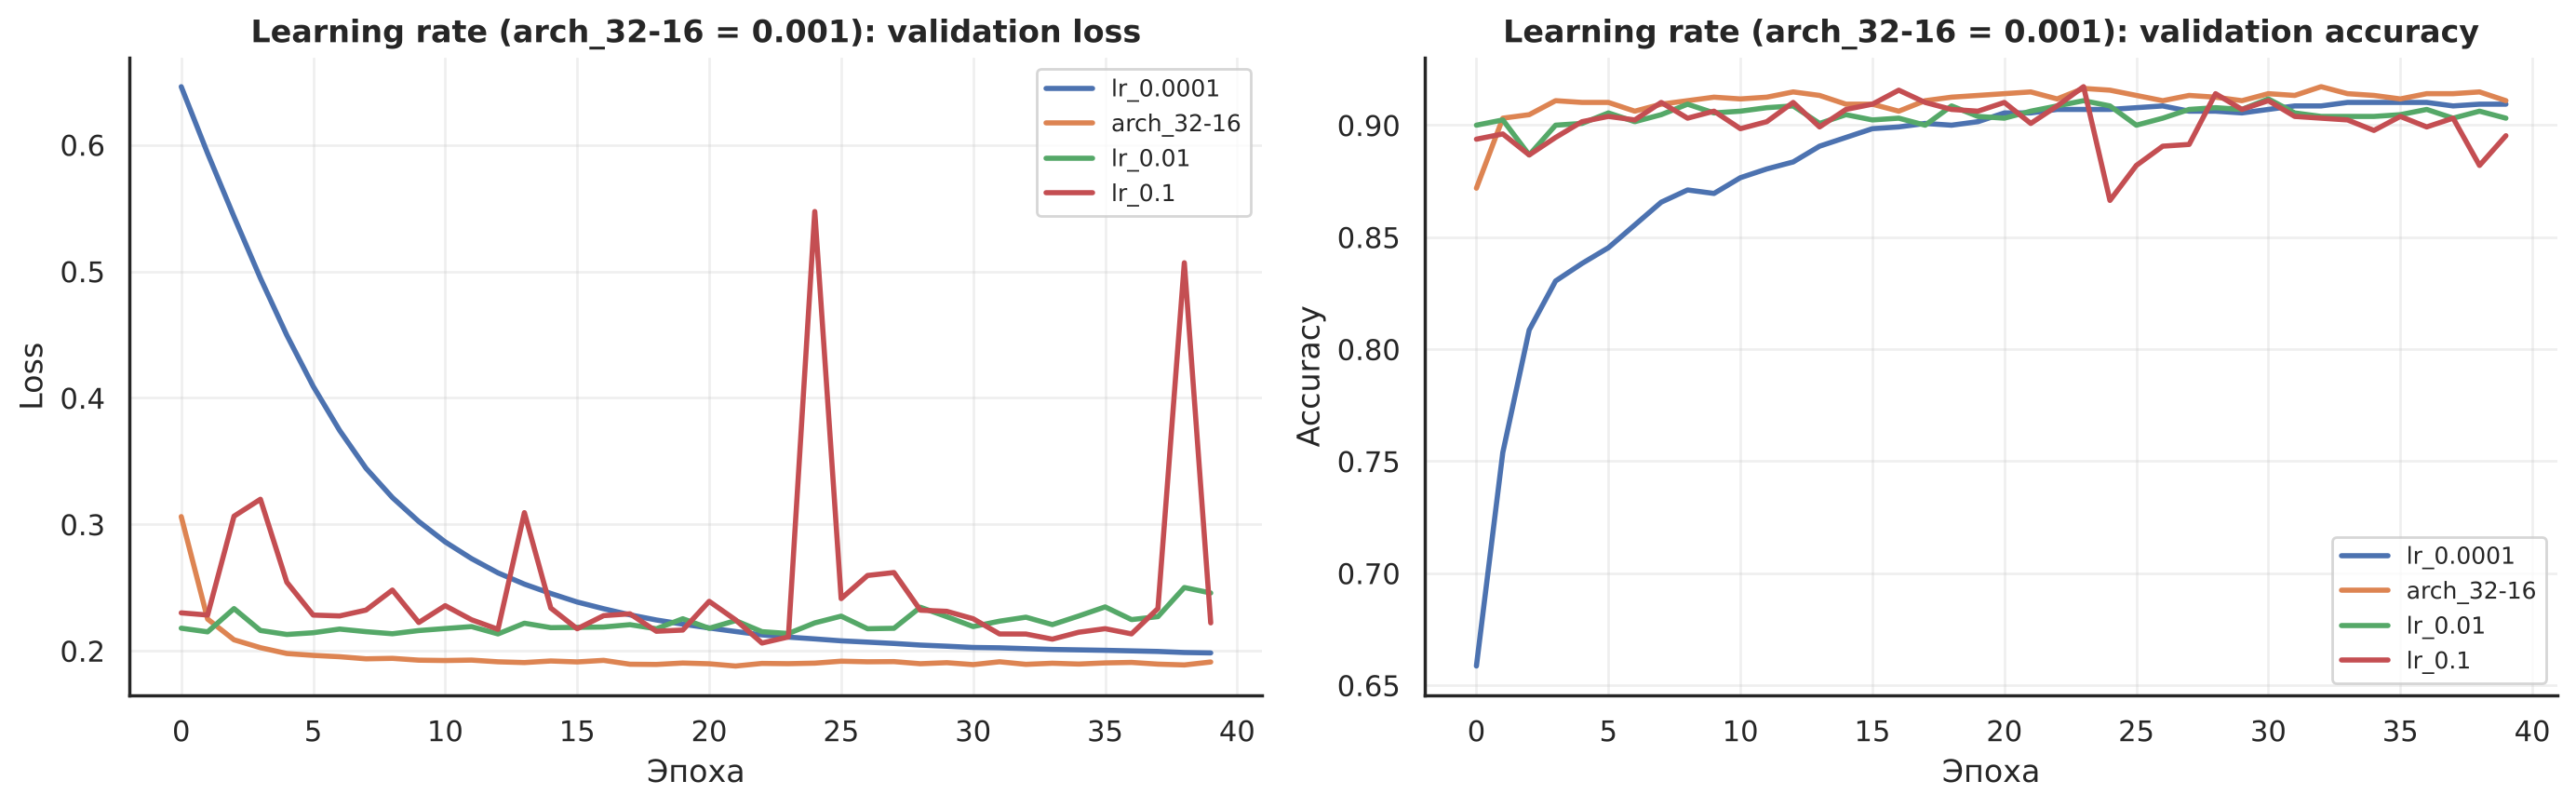

,lr,train_acc,val_acc,val_f1,val_loss,min_val_loss,best_epoch
lr_0.0001,0.0001,0.900781,0.909375,0.920873,0.198389,0.198389,40
arch_32-16,0.001,0.92168,0.910937,0.920943,0.191212,0.188018,22
lr_0.01,0.01,0.92207,0.903125,0.913165,0.245767,0.212986,5
lr_0.1,0.1,0.856836,0.895312,0.911493,0.222134,0.206183,23


In [30]:
print('--- Эксперимент 5: скорость обучения (learning rate) ---')
lr_runs = ['lr_0.0001', 'arch_32-16', 'lr_0.01', 'lr_0.1']
for lr in [1e-4, 1e-2, 1e-1]:
    run_experiment(f'lr_{lr:g}', lr=lr)
plot_runs(lr_runs, 'Learning rate (arch_32-16 = 0.001)')
runs_table(lr_runs)[['lr', 'train_acc', 'val_acc', 'val_f1', 'val_loss', 'min_val_loss', 'best_epoch']]

### 5.6. Скорость обучения

- **0.0001** — слишком медленно: за 40 эпох сеть не сошлась (loss 0.198 и продолжает снижаться, train accuracy 0.901).
- **0.001** — оптимум: min loss 0.188.
- **0.01** — быстрый старт (минимум loss 0.213 уже на 5-й эпохе), затем сильное переобучение: validation loss растёт до 0.246.
- **0.1** — шаг слишком велик: обучение нестабильно, train accuracy всего 0.857, validation accuracy 0.895.

Скорость обучения оказалась самым влиятельным гиперпараметром после размера сети.

In [31]:
all_tbl = runs_table([n for n in nn_runs if not n.startswith('base_')])
all_tbl = all_tbl.sort_values('min_val_loss')
print('Все эксперименты (40 эпох), отсортированы по минимальному validation loss:')
print(all_tbl[['hidden', 'activation', 'lr', 'batch_size', 'val_acc', 'val_f1', 'min_val_loss', 'best_epoch']].to_string())
best_name = all_tbl.index[0]
best_cfg = nn_runs[best_name]
print('\nЛучшая конфигурация:', best_name)

Все эксперименты (40 эпох), отсортированы по минимальному validation loss:
                       hidden activation      lr batch_size   val_acc    val_f1 min_val_loss best_epoch
act_elu              (32, 16)        elu   0.001         32  0.916406  0.926258     0.184433         38
bs_128               (32, 16)       relu   0.001        128  0.915625   0.92633     0.187179         36
arch_16                 (16,)       relu   0.001         32  0.913281  0.923816     0.187292         40
arch_32-16           (32, 16)       relu   0.001         32  0.910937  0.920943     0.188018         22
act_tanh             (32, 16)       tanh   0.001         32  0.914844  0.924879     0.191444         27
bs_512               (32, 16)       relu   0.001        512  0.911719  0.922972     0.191577         40
act_sigmoid          (32, 16)    sigmoid   0.001         32  0.908594  0.919366     0.191953         40
bs_16                (32, 16)       relu   0.001         16  0.904688  0.914804     0.192286 

### 5.7. Итог экспериментов и финальная модель

Сводная таблица всех конфигураций, отсортированная по минимальному validation loss. Лучшая — **32-16 с активацией ELU** (min loss 0.184, validation accuracy 0.916). В целом разброс между разумными конфигурациями мал (accuracy 0.905–0.916); заметно проигрывают только слишком большая сеть и слишком большая скорость обучения.

In [32]:
# Финальная сеть: лучшая конфигурация + ранняя остановка по validation loss
keras.utils.set_random_seed(SEED)
model_final = build_nn(best_cfg['hidden'], best_cfg['activation'], best_cfg['lr'])
callbacks = [
    keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_ROOT, 'final_' + best_name)),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
]
hist_final = model_final.fit(X_nn_train, y_nn_train, validation_data=(X_nn_val, y_nn_val),
                             batch_size=best_cfg['batch_size'], epochs=100, callbacks=callbacks, verbose=0)
print('Обучение остановлено на эпохе', len(hist_final.history['loss']),
      '| лучшая эпоха:', int(np.argmin(hist_final.history['val_loss'])) + 1)

nn_proba = model_final.predict(X_test_prep, verbose=0).ravel()
nn_pred = (nn_proba >= 0.5).astype(int)
nn_metrics = get_metrics(y_test, nn_pred, nn_proba)
print('Нейронная сеть на тесте:', {k: round(float(v), 4) for k, v in zip(METRIC_COLS, nn_metrics)})
print('Матрица ошибок:\n', confusion_matrix(y_test, nn_pred))

Обучение остановлено на эпохе 48 | лучшая эпоха: 38
Нейронная сеть на тесте: {'Accuracy': 0.9269, 'Precision': 0.9357, 'Recall': 0.9368, 'F1': 0.9362, 'AUC': 0.9826}
Матрица ошибок:
 [[624  59]
 [ 58 859]]


Финальная сеть обучена с лучшей конфигурацией и колбэком `EarlyStopping`: обучение прекращается, если validation loss не улучшается 10 эпох подряд, и восстанавливаются веса лучшей эпохи. Это автоматизирует выбор числа эпох и защищает от переобучения. Обучение остановилось на 48-й эпохе, восстановлены веса 38-й.

Результат на тестовой выборке: **accuracy 0.927, precision 0.936, recall 0.937, F1 0.936, AUC 0.983**. Ошибки распределены симметрично: 59 ложных тревог и 58 пропусков из 1600 объектов.

### 5.8. Мониторинг обучения в TensorBoard

Все эксперименты записаны в папку `logs/fit`. Запуск TensorBoard:

- в терминале из папки с ноутбуком: `tensorboard --logdir logs/fit`, затем открыть http://localhost:6006;
- либо прямо в ноутбуке — раскомментировать две строки в ячейке ниже.

Что смотреть:

- вкладка **Scalars** — графики `epoch_loss` и `epoch_accuracy`; для каждого эксперимента есть две кривые: `train` и `validation`. Слева можно отметить нужные запуски (например, все `arch_*`), чтобы сравнить их на одном графике;
- вкладка **Histograms / Distributions** (для запуска `base_32-16_relu_100ep`) — как меняются распределения весов слоёв по эпохам;
- вкладка **Graphs** — граф вычислений модели.

In [33]:
# Запуск TensorBoard прямо в ноутбуке (Jupyter / VS Code / Colab): раскомментируйте две строки ниже.
# Альтернатива — в терминале из папки с ноутбуком:  tensorboard --logdir logs/fit
# и открыть в браузере http://localhost:6006

# %load_ext tensorboard
# %tensorboard --logdir logs/fit

print('Логи TensorBoard:')
for d in sorted(os.listdir(LOG_ROOT)):
    print('  ', os.path.join(LOG_ROOT, d))

Логи TensorBoard:
   logs/fit/act_elu
   logs/fit/act_sigmoid
   logs/fit/act_tanh
   logs/fit/arch_128-64-32
   logs/fit/arch_16
   logs/fit/arch_32-16
   logs/fit/arch_64-32
   logs/fit/base_32-16_relu_100ep
   logs/fit/bs_128
   logs/fit/bs_16
   logs/fit/bs_512
   logs/fit/final_act_elu
   logs/fit/lr_0.0001
   logs/fit/lr_0.01
   logs/fit/lr_0.1


> **Место для скриншотов TensorBoard.** Вставьте сюда снимки вкладки Scalars (`epoch_loss` и `epoch_accuracy`) — например, для запусков `base_32-16_relu_100ep` и группы `arch_*`.

Графики TensorBoard повторяют выводы разделов 5.2–5.6: на кривых базовой модели `train`-loss монотонно убывает, а `validation`-loss после ~20-й эпохи начинает расти; при совмещении запусков `arch_*` видно, что кривая validation loss сети 128-64-32 уходит вверх с первых эпох, а у `lr_0.0001` обе кривые к 40-й эпохе ещё не вышли на плато.

## 6. Сравнительный анализ

Итоговое сравнение на тестовой выборке:
                Accuracy  Precision  Recall      F1     AUC
Model                                                      
SVM               0.9338     0.9346  0.9509  0.9427  0.9826
Neural Network    0.9269     0.9357  0.9368  0.9362  0.9826
LDA               0.9131     0.9192  0.9302  0.9247  0.9756
kNN               0.8950     0.8971  0.9226  0.9097  0.9552
DecisionTree      0.8612     0.8499  0.9204  0.8838  0.9445
GaussianNB        0.8125     0.8184  0.8648  0.8409  0.8703


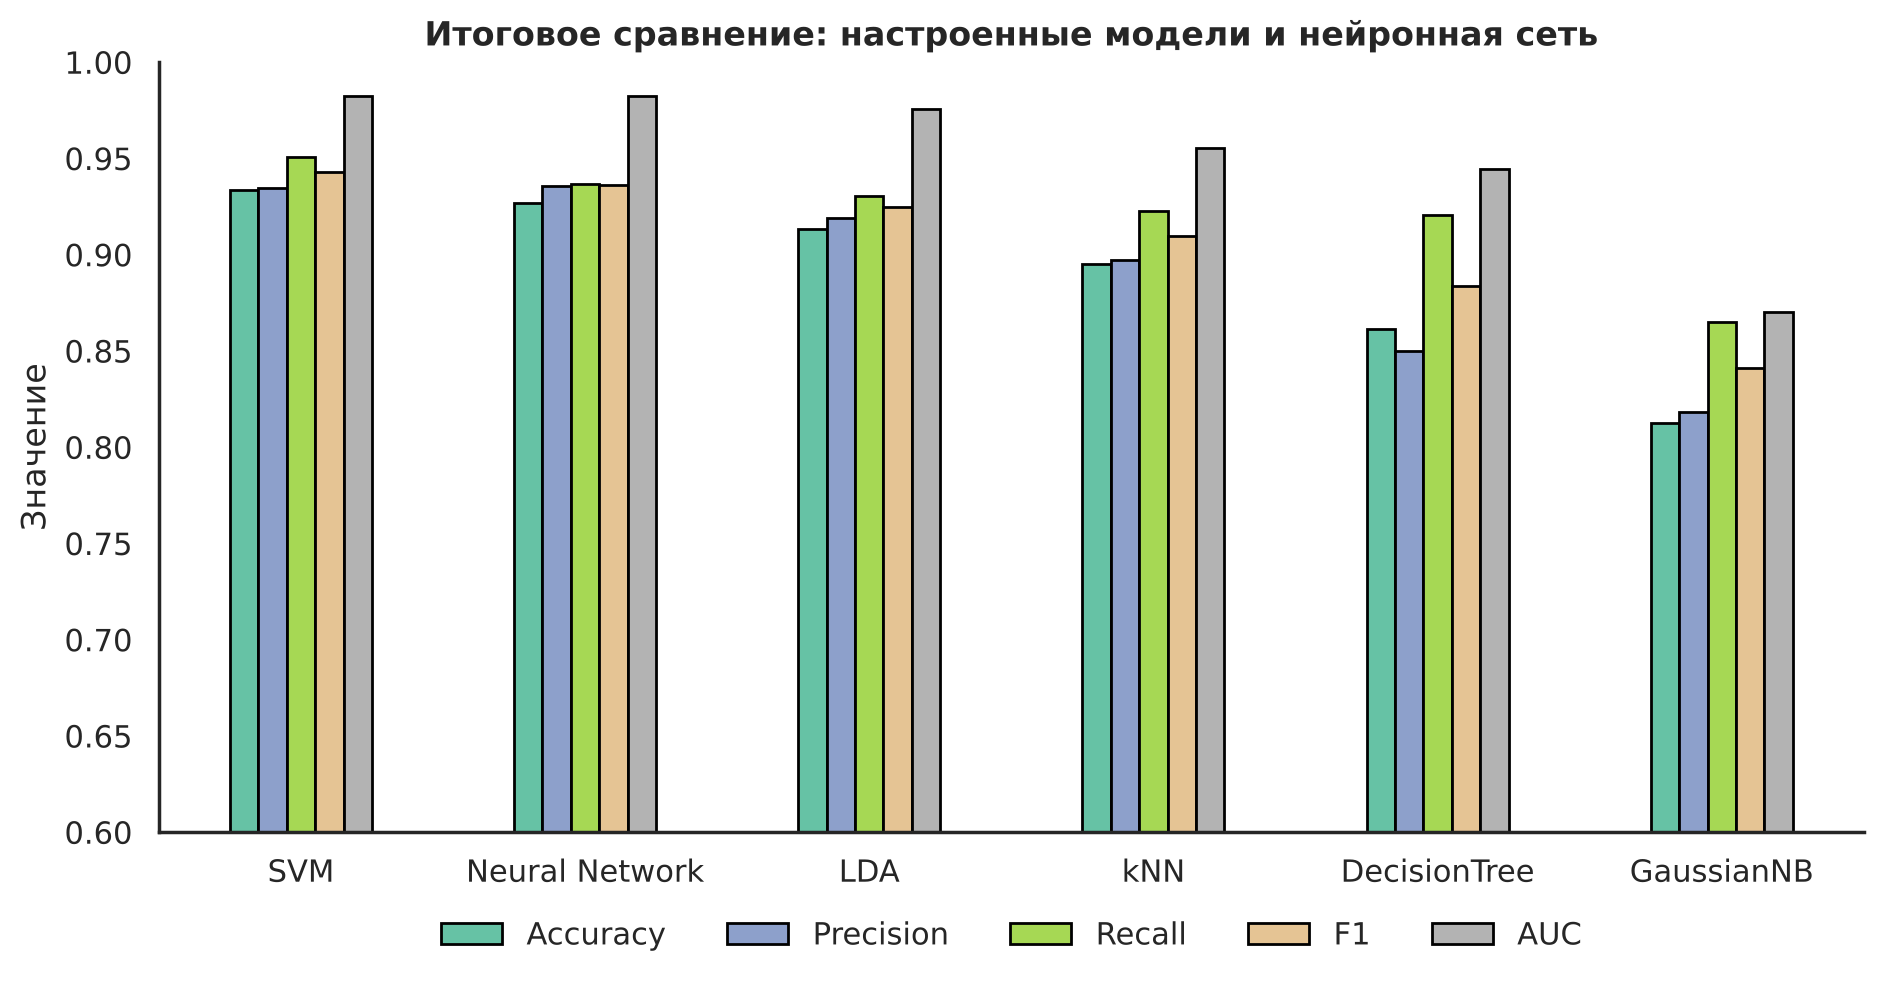

In [34]:
compare_df = final_df.copy()
compare_df.loc['Neural Network'] = nn_metrics
compare_df = compare_df.sort_values('F1', ascending=False)
print('Итоговое сравнение на тестовой выборке:')
print(compare_df.round(4))

ax = compare_df[METRIC_COLS].plot(kind='bar', figsize=(11, 5), ylim=(0.6, 1.0),
                                  colormap='Set2', edgecolor='black')
plt.title('Итоговое сравнение: настроенные модели и нейронная сеть', fontweight='bold')
plt.ylabel('Значение'); plt.xlabel(''); plt.xticks(rotation=0)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=5, frameon=False)
plt.show()

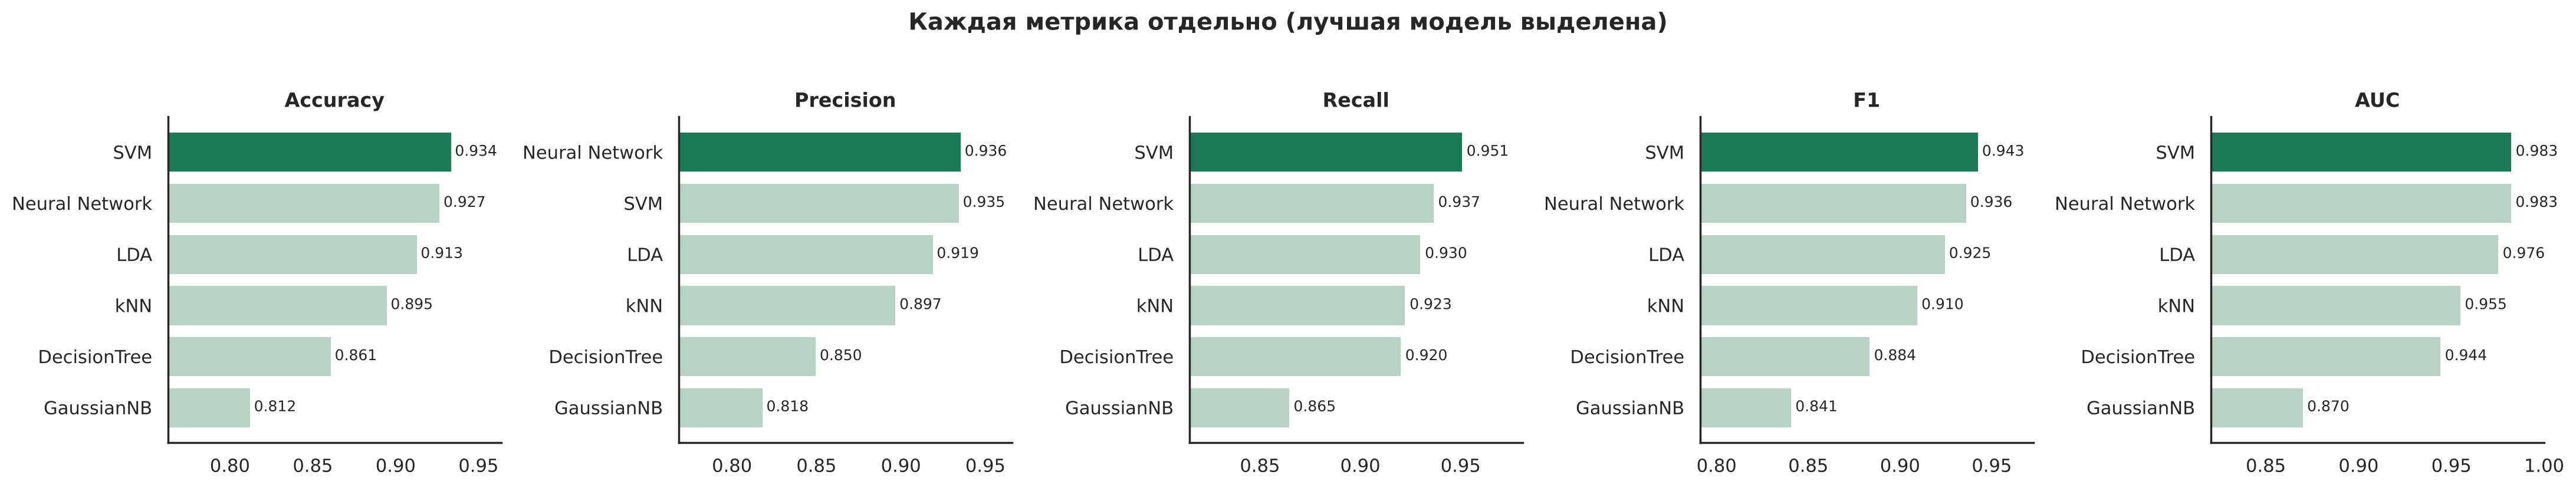

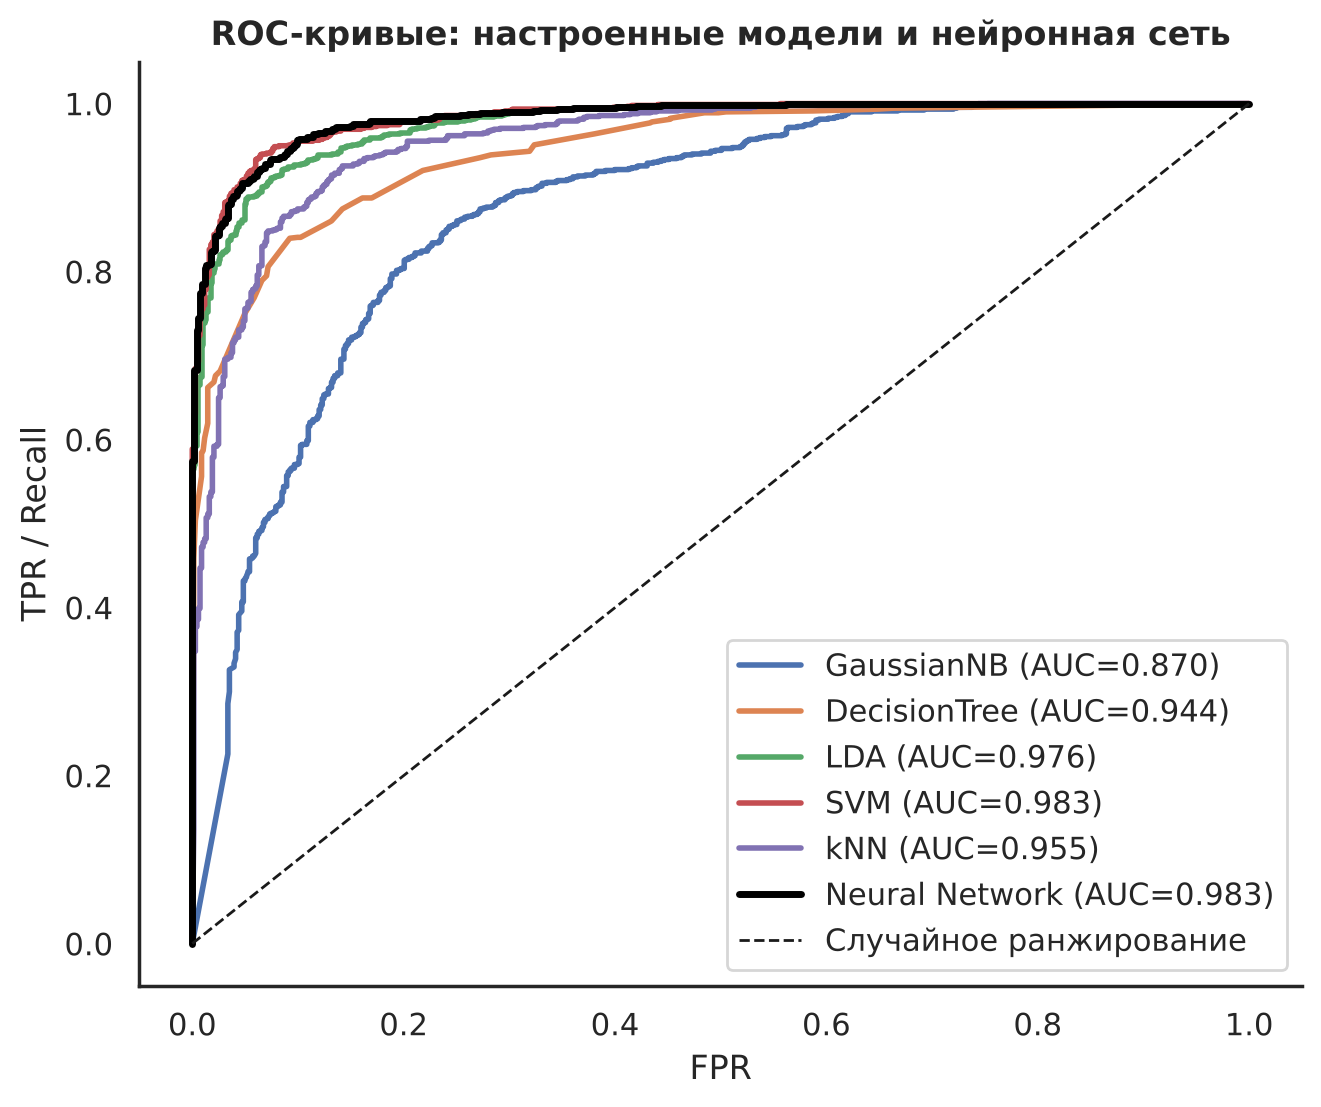

In [35]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, metric in zip(axes, METRIC_COLS):
    s = compare_df[metric].sort_values()
    colors = ['#1a7a57' if v == s.max() else '#b7d3c6' for v in s.values]
    ax.barh(s.index, s.values, color=colors)
    lo = max(0, s.min() - 0.05)
    ax.set_xlim(lo, min(1.0, s.max() + 0.03))
    for i, v in enumerate(s.values):
        ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)
    ax.set_title(metric, fontweight='bold')
plt.suptitle('Каждая метрика отдельно (лучшая модель выделена)', fontweight='bold', y=1.03)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7.5, 6))
for name in best_models:
    fpr, tpr, _ = roc_curve(y_test, proba_tuned[name])
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC={roc_auc_score(y_test, proba_tuned[name]):.3f})')
fpr, tpr, _ = roc_curve(y_test, nn_proba)
plt.plot(fpr, tpr, lw=2.5, color='black', label=f'Neural Network (AUC={nn_metrics[-1]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Случайное ранжирование')
plt.xlabel('FPR'); plt.ylabel('TPR / Recall')
plt.title('ROC-кривые: настроенные модели и нейронная сеть', fontweight='bold')
plt.legend(loc='lower right'); plt.show()

Итоговая таблица (тестовая выборка, 1600 объектов; классические модели — после подбора гиперпараметров):

| Модель | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| **SVM** (RBF, C=10, gamma=0.01) | **0.9338** | 0.9346 | **0.9509** | **0.9427** | **0.9826** |
| Нейронная сеть (32-16, ELU) | 0.9269 | **0.9357** | 0.9368 | 0.9362 | **0.9826** |
| LDA | 0.9131 | 0.9192 | 0.9302 | 0.9247 | 0.9756 |
| kNN (k=31, distance) | 0.8950 | 0.8971 | 0.9226 | 0.9097 | 0.9552 |
| Дерево решений (depth=7, leaf=20) | 0.8612 | 0.8499 | 0.9204 | 0.8838 | 0.9445 |
| GaussianNB | 0.8125 | 0.8184 | 0.8648 | 0.8409 | 0.8703 |

**Лучший подход для данного датасета — метод опорных векторов с RBF-ядром.** Он лидирует по accuracy, recall и F1 и делит первое место по AUC с нейронной сетью. Аргументы:

1. **Качество.** SVM ошибается на 106 объектах из 1600, нейросеть — на 117, LDA — на 139. Разница между SVM и нейросетью невелика (0.7 п.п. accuracy, 11 объектов) и сопоставима со случайным разбросом, но SVM не уступает сети ни по одной метрике, кроме precision (на 0.001).
2. **Простота настройки.** У SVM два гиперпараметра, и уже значения по умолчанию давали F1 = 0.940. Нейросеть потребовала выбора архитектуры, активации, батча, скорости обучения и числа эпох и при этом не превзошла SVM.
3. **Структура данных.** Классы почти линейно разделимы: линейная модель LDA без какой-либо настройки даёт F1 = 0.925, а линейное ядро SVM не уступает RBF на кросс-валидации. Поэтому сложные модели (глубокая сеть, глубокое дерево) не получают преимущества и лишь быстрее переобучаются.

Почему остальные методы слабее:

- **kNN** страдает от размерности: в 26-мерном пространстве, где часть признаков (возраст, фоновая тревожность, пол) почти не связана с целью, расстояния «зашумлены» неинформативными координатами.
- **Дерево решений** аппроксимирует наклонную границу ступеньками по осям, что для почти линейной зависимости неэффективно; без ограничений глубины оно запоминает выборку.
- **GaussianNB** — худший результат: предположение о независимости признаков явно нарушено (корреляции до 0.87 между признаками реакции организма). LDA, который отличается от него именно учётом ковариаций, выигрывает 8 п.п. F1; при `shrinkage = 1` LDA опускается до уровня наивного Байеса.

## Заключение

В ходе лабораторной работы решена задача бинарной классификации — прогноз выраженного кофеинового спада по датасету «Caffeine Crash and Anxiety Telemetry» (8000 наблюдений).

1. **Подготовка данных.** Четыре исходных уровня спада объединены в бинарную целевую переменную (57.3% / 42.7%). Обнаружена и устранена утечка целевой переменной: признак `crash_severity_score` однозначно определял класс. Числовые признаки стандартизованы, категориальные закодированы через One-Hot (26 признаков); выборка разбита на обучающую и тестовую в соотношении 80 / 20 со стратификацией.
2. **Классические методы.** Построены и сравнены по пяти метрикам наивный Байес (четыре варианта, лучший — GaussianNB), дерево решений, LDA, SVM и kNN.
3. **Гиперпараметры.** Подбор по сетке с 5-фолдовой кросс-валидацией сильнее всего улучшил дерево решений (F1 0.843 → 0.884) и kNN (0.886 → 0.910); SVM, LDA и GaussianNB оказались близки к оптимуму уже с параметрами по умолчанию. Кривые валидации наглядно показали переобучение при большой глубине дерева, малом k, больших C и gamma.
4. **Нейронная сеть.** Реализован многослойный перцептрон на TensorFlow / Keras; исследовано влияние числа эпох, архитектуры, функции активации, размера батча и скорости обучения, ход обучения записан в TensorBoard. Лучшая конфигурация — два скрытых слоя 32-16 с ELU, Adam (0.001), батч 32, ранняя остановка; увеличение сети и скорости обучения приводило к переобучению.
5. **Итог.** Лучшее качество на тесте показал SVM с RBF-ядром (accuracy 0.934, F1 0.943, AUC 0.983); нейронная сеть практически не уступает (0.927 / 0.936 / 0.983), далее идут LDA, kNN, дерево решений и GaussianNB. Для табличных данных небольшого объёма с почти линейной границей между классами хорошо настроенный классический метод оказывается не хуже нейронной сети и проще в настройке.